HASTINGS DIRECT TECHNICAL SECTION
FRAUD TASK

In [1]:
# I imported the libraries I need for data manipulation, cleaning and visuals
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Next, I import the Task Data and read the dataframe
df = pd.read_excel("Data Task.xlsx", sheet_name="Data")
df

,id,start_date,exposure,net_earned_premium,net_written_premium,claim_count,is_capped_incurred,incurred,capped_incurred,bi_incurred,...,transmission,region,gender,vehicle_purchase_date,licence_test_date,primary_car_colour,high_value_threshold,payment_type,investigation_flag,fraud_flag
0,1,23/03/2020,0.106849,42.18204,394.7806,0,NaN,NaN,NaN,NaN,...,MANUAL,South West,Male,42741,29/02/2012,Black,14172.50,Annual,0,0
1,2,43800,1.000000,133.33050,133.3305,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,East Anglia,Female,43800,34669,Silver,2000.00,DD,0,0
2,3,15/06/2018,1.000000,728.94960,728.9496,0,NaN,NaN,NaN,NaN,...,MANUAL,East Midlands,Female,15/06/2018,15/06/2009,NaN,28187.75,DD,0,0
3,4,14/05/2018,1.000000,456.93180,456.9318,0,NaN,NaN,NaN,NaN,...,MANUAL,West Midlands,Male,42379,40030,Black,4500.00,DD,0,0
4,5,43443,1.000000,498.36620,498.3662,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,North West,Male,43443,35042,Black,18458.75,Annual,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,43171,1.000000,377.39120,196.0342,0,NaN,NaN,NaN,NaN,...,MANUAL,West Midlands,Male,15/05/2019,35500,Black,13268.50,Annual,0,0
99996,99997,26/01/2019,1.000000,390.87250,390.8725,0,NaN,NaN,NaN,NaN,...,MANUAL,Outer London,Male,42014,41194,Silver,7500.00,Annual,0,0
99997,99998,24/09/2019,0.601093,836.85400,1423.4940,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,West Midlands,Male,43839,43013,Black,9989.75,DD,0,0
99998,99999,30/09/2018,1.000000,187.06230,195.6380,0,NaN,NaN,NaN,NaN,...,MANUAL,Scotland,Male,18/03/2019,31/08/1994,NaN,9000.00,Annual,0,0


DESCRIPTIVE ANALYSIS
To understand the data structure and the data types of each variable

In [3]:
# I get an overview of the data frame and the structure (data types, non-null values, column names)
df.head()

,id,start_date,exposure,net_earned_premium,net_written_premium,claim_count,is_capped_incurred,incurred,capped_incurred,bi_incurred,...,transmission,region,gender,vehicle_purchase_date,licence_test_date,primary_car_colour,high_value_threshold,payment_type,investigation_flag,fraud_flag
0,1,23/03/2020,0.106849,42.18204,394.7806,0,NaN,NaN,NaN,NaN,...,MANUAL,South West,Male,42741,29/02/2012,Black,14172.50,Annual,0,0
1,2,43800,1.000000,133.33050,133.3305,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,East Anglia,Female,43800,34669,Silver,2000.00,DD,0,0
2,3,15/06/2018,1.000000,728.94960,728.9496,0,NaN,NaN,NaN,NaN,...,MANUAL,East Midlands,Female,15/06/2018,15/06/2009,NaN,28187.75,DD,0,0
3,4,14/05/2018,1.000000,456.93180,456.9318,0,NaN,NaN,NaN,NaN,...,MANUAL,West Midlands,Male,42379,40030,Black,4500.00,DD,0,0
4,5,43443,1.000000,498.36620,498.3662,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,North West,Male,43443,35042,Black,18458.75,Annual,0,0


In [4]:
# This gives a summary statistics of the numerical columns in the data
df.describe(include="all").T
# I transposed my describe function so that each feature is a row and then the summary stats are on the columns
# for easier comaprison and interpretation

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,100000.0,NaN,NaN,NaN,50000.5,28867.657797,1.0,25000.75,50000.5,75000.25,100000.0
start_date,100000.0,731.0,43108.0,397.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exposure,100000.0,NaN,NaN,NaN,0.719509,0.344445,0.002732,0.439891,0.937159,1.0,1.0
net_earned_premium,99977.0,NaN,NaN,NaN,273.504717,251.903597,-1134.753,114.4464,207.4362,360.8297,3912.24
net_written_premium,100000.0,NaN,NaN,NaN,365.732809,282.806083,0.0,182.4435,286.25415,458.0214,4394.661
claim_count,100000.0,NaN,NaN,NaN,0.07964,0.292298,0.0,0.0,0.0,0.0,4.0
is_capped_incurred,7396.0,NaN,NaN,NaN,0.001622,0.04025,0.0,0.0,0.0,0.0,1.0
incurred,7396.0,NaN,NaN,NaN,2854.035429,10711.181422,-1854.64,34.5,159.5,2968.7375,489297.5
capped_incurred,7396.0,NaN,NaN,NaN,2646.017693,5433.148511,-1854.64,34.5,159.5,2968.7375,55259.6
bi_incurred,7396.0,NaN,NaN,NaN,1011.56454,9718.401469,0.0,0.0,0.0,0.0,478339.3


DATA CLEANING AND QUALITY CHECKS

In [5]:
 # DATA CONSISTENCY
 # First, I checked that the name and number of rows and columns is consistent with the data file I have
df.info()  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      100000 non-null  int64  
 1   start_date              100000 non-null  object 
 2   exposure                100000 non-null  float64
 3   net_earned_premium      99977 non-null   float64
 4   net_written_premium     100000 non-null  float64
 5   claim_count             100000 non-null  int64  
 6   is_capped_incurred      7396 non-null    float64
 7   incurred                7396 non-null    float64
 8   capped_incurred         7396 non-null    float64
 9   bi_incurred             7396 non-null    float64
 10  ad_incurred             7396 non-null    float64
 11  pd_incurred             7396 non-null    float64
 12  th_incurred             7396 non-null    float64
 13  ws_incurred             7396 non-null    float64
 14  bi_count             

In [6]:
# MISSING VALUES
# I checked for missing values in each of the columns and displayed them as a percentage of the entire rows
df.isna().mean().sort_values(ascending=True)

id                        0.00000
start_date                0.00000
exposure                  0.00000
net_written_premium       0.00000
claim_count               0.00000
d1_age                    0.00000
vehicle_age               0.00000
vehicle_annual_mileage    0.00000
vehicle_use               0.00000
entitlement               0.00000
overnight_location        0.00000
pncd                      0.00000
cover                     0.00000
voluntary_xs              0.00000
ncd                       0.00000
business_provider         0.00000
vehicle_value             0.00000
payment_type              0.00000
fraud_flag                0.00000
investigation_flag        0.00000
gender                    0.00000
vehicle_purchase_date     0.00000
d1_is_uk_resident         0.00000
d1_residency_years        0.00000
licence_test_date         0.00007
net_earned_premium        0.00023
region                    0.00142
vehicle_make              0.00771
high_value_threshold      0.00771
transmission  

In [7]:
# CHECK FOR DUPLICATE RECORDS
df.duplicated().sum()

np.int64(0)

In [8]:
# Here, I cleaned the data to remove whitespace, standardise missing values, and ensure correct data types
df = df.applymap(lambda x: pd.to_numeric(str(x).replace(",", "").strip(), errors="ignore") if isinstance(x, str) else x).replace(["NA","na","NaN","n/a","","null","NULL"], pd.NA)
df

C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\477924612.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: pd.to_numeric(str(x).replace(",", "").strip(), errors="ignore") if isinstance(x, str) else x).replace(["NA","na","NaN","n/a","","null","NULL"], pd.NA)
C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\477924612.py:2: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df = df.applymap(lambda x: pd.to_numeric(str(x).replace(",", "").strip(), errors="ignore") if isinstance(x, str) else x).replace(["NA","na","NaN","n/a","","null","NULL"], pd.NA)


,id,start_date,exposure,net_earned_premium,net_written_premium,claim_count,is_capped_incurred,incurred,capped_incurred,bi_incurred,...,transmission,region,gender,vehicle_purchase_date,licence_test_date,primary_car_colour,high_value_threshold,payment_type,investigation_flag,fraud_flag
0,1,23/03/2020,0.106849,42.18204,394.7806,0,NaN,NaN,NaN,NaN,...,MANUAL,South West,Male,42741,29/02/2012,Black,14172.50,Annual,0,0
1,2,43800,1.000000,133.33050,133.3305,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,East Anglia,Female,43800,34669,Silver,2000.00,DD,0,0
2,3,15/06/2018,1.000000,728.94960,728.9496,0,NaN,NaN,NaN,NaN,...,MANUAL,East Midlands,Female,15/06/2018,15/06/2009,NaN,28187.75,DD,0,0
3,4,14/05/2018,1.000000,456.93180,456.9318,0,NaN,NaN,NaN,NaN,...,MANUAL,West Midlands,Male,42379,40030,Black,4500.00,DD,0,0
4,5,43443,1.000000,498.36620,498.3662,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,North West,Male,43443,35042,Black,18458.75,Annual,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,43171,1.000000,377.39120,196.0342,0,NaN,NaN,NaN,NaN,...,MANUAL,West Midlands,Male,15/05/2019,35500,Black,13268.50,Annual,0,0
99996,99997,26/01/2019,1.000000,390.87250,390.8725,0,NaN,NaN,NaN,NaN,...,MANUAL,Outer London,Male,42014,41194,Silver,7500.00,Annual,0,0
99997,99998,24/09/2019,0.601093,836.85400,1423.4940,0,NaN,NaN,NaN,NaN,...,AUTOMATIC,West Midlands,Male,43839,43013,Black,9989.75,DD,0,0
99998,99999,30/09/2018,1.000000,187.06230,195.6380,0,NaN,NaN,NaN,NaN,...,MANUAL,Scotland,Male,18/03/2019,31/08/1994,NaN,9000.00,Annual,0,0


In [59]:
#CHECK FOR DATE VALIDITY - TO PRODUCE RELIABLE DATES FOR MY TIME-BASED ANALYSES
# I noticed that some date values were incorrect as some used Excel serials and some others didn't apply the correct date string for pandas. 
# So I defined a parsing function to clean and correct date type so I can make further validation checks for my date columns.
def parse_any_date_clean(
    s: pd.Series,
    *,
    dayfirst: bool = True,
    normalize: bool = True,
    serial_min: int = 10000,
    serial_max: int = 70000,
    min_year: int | None = None,
    max_year: int | None = None,
) -> pd.Series:
    
    # I encountered lots of errors especially in parsing the vehicle purchase date column so I concluded the values need to be cleaned before parsing and it worked.
    # However, I did it for all date columns. So I:

    # 1. Pre-cleaned text to remove commas, separators & spaces
    s_clean = s.astype(str).str.strip().str.replace(",", "", regex=False)
    s_clean = s_clean.replace({"": np.nan, "NA": np.nan, "NaN": np.nan})

    # 2. Using normal date parsing for strings/datetimes
    dt_str = pd.to_datetime(s_clean, errors="coerce", dayfirst=dayfirst)

    # 3. Then with Excel serials for numeric-looking values (including digits with a single dot e.g "42741.0"
    numeric_like = s_clean.str.fullmatch(r"\d+(\.\d+)?")
    num = pd.to_numeric(s_clean.where(numeric_like), errors="coerce")
    serial_mask = num.between(serial_min, serial_max)

    dt_xls = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    if serial_mask.any():
        dt_xls.loc[serial_mask] = pd.to_datetime(
            num.loc[serial_mask],
            unit="D",
            origin="1899-12-30",
            errors="coerce"
        )

    # 3) If normal parsing fails, it falls back to Excel serials logic to ensure I capture all valid dates
    out = dt_str.fillna(dt_xls)

    # 4) Clamp the period such that dates like 1753-01-01 which is below min_year will become null
    if min_year is not None:
        out = out.mask(out < pd.Timestamp(f"{min_year}-01-01"))
    if max_year is not None:
        out = out.mask(out > pd.Timestamp(f"{max_year}-12-31"))

    # 5) Normalised to YYYY-MM-DD format
    if normalize:
        out = out.dt.normalize()

    return out

In [61]:
# I kept the original columns before parsing for transparency and auditing
df["start_date_raw"] = df["start_date"]
df["licence_test_date_raw"] = df["licence_test_date"]
df["vehicle_purchase_date_raw"] = df["vehicle_purchase_date"]

df["start_date"] = parse_any_date_clean(df["start_date"], min_year=2016, max_year=2025)
df["licence_test_date"] = parse_any_date_clean(df["licence_test_date"], min_year=1950, max_year=2025)
df["vehicle_purchase_date"] = parse_any_date_clean(df["vehicle_purchase_date"], min_year=1980, max_year=2025)

C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\1725339466.py:23: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_str = pd.to_datetime(s_clean, errors="coerce", dayfirst=dayfirst)
C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\1725339466.py:23: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dt_str = pd.to_datetime(s_clean, errors="coerce", dayfirst=dayfirst)


In [62]:
# I checked the first 20 rows of the now cleaned date columns
df[["start_date", "licence_test_date", "vehicle_purchase_date"]].head(50)

,start_date,licence_test_date,vehicle_purchase_date
0,2020-03-23,2012-02-29,2017-01-06
1,2019-12-01,1994-12-01,2019-12-01
2,2018-06-15,2009-06-15,NaT
3,2018-05-14,2009-08-05,2016-01-10
4,2018-12-09,1995-12-09,2018-12-09
5,2018-06-23,2016-05-23,2017-01-01
6,2018-11-21,1975-04-14,2018-01-08
7,2020-11-03,2000-11-03,2020-01-03
8,2018-07-20,2016-09-20,2016-01-10
9,2019-02-23,2015-05-02,2019-01-01


In [63]:
# Then, I viewed the entire dataframe again to observe changes made
df

,id,start_date,exposure,net_earned_premium,net_written_premium,claim_count,is_capped_incurred,incurred,capped_incurred,bi_incurred,...,primary_car_colour,high_value_threshold,payment_type,investigation_flag,fraud_flag,start_date_raw,licence_test_date_raw,vehicle_purchase_date_raw,policy_year,policy_month_dt
0,1,2020-03-23,0.106849,42.18204,394.7806,0,NaN,NaN,NaN,NaN,...,Black,14172.50,Annual,0,0,2020-03-23,2012-02-29,2017-06-01,2020,2020-03-01
1,2,2019-12-01,1.000000,133.33050,133.3305,0,NaN,NaN,NaN,NaN,...,Silver,2000.00,DD,0,0,2019-12-01,1994-12-01,2019-01-12,2019,2019-12-01
2,3,2018-06-15,1.000000,728.94960,728.9496,0,NaN,NaN,NaN,NaN,...,NaN,28187.75,DD,0,0,2018-06-15,2009-06-15,NaT,2018,2018-06-01
3,4,2018-05-14,1.000000,456.93180,456.9318,0,NaN,NaN,NaN,NaN,...,Black,4500.00,DD,0,0,2018-05-14,2009-08-05,2016-10-01,2018,2018-05-01
4,5,2018-12-09,1.000000,498.36620,498.3662,0,NaN,NaN,NaN,NaN,...,Black,18458.75,Annual,0,0,2018-12-09,1995-12-09,2018-09-12,2018,2018-12-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,2018-03-12,1.000000,377.39120,196.0342,0,NaN,NaN,NaN,NaN,...,Black,13268.50,Annual,0,0,2018-03-12,1997-03-11,NaT,2018,2018-03-01
99996,99997,2019-01-26,1.000000,390.87250,390.8725,0,NaN,NaN,NaN,NaN,...,Silver,7500.00,Annual,0,0,2019-01-26,2012-10-12,2015-10-01,2019,2019-01-01
99997,99998,2019-09-24,0.601093,836.85400,1423.4940,0,NaN,NaN,NaN,NaN,...,Black,9989.75,DD,0,0,2019-09-24,2017-10-05,2020-09-01,2019,2019-09-01
99998,99999,2018-09-30,1.000000,187.06230,195.6380,0,NaN,NaN,NaN,NaN,...,NaN,9000.00,Annual,0,0,2018-09-30,1994-08-31,NaT,2018,2018-09-01


EXPLORATORY ANALYSIS

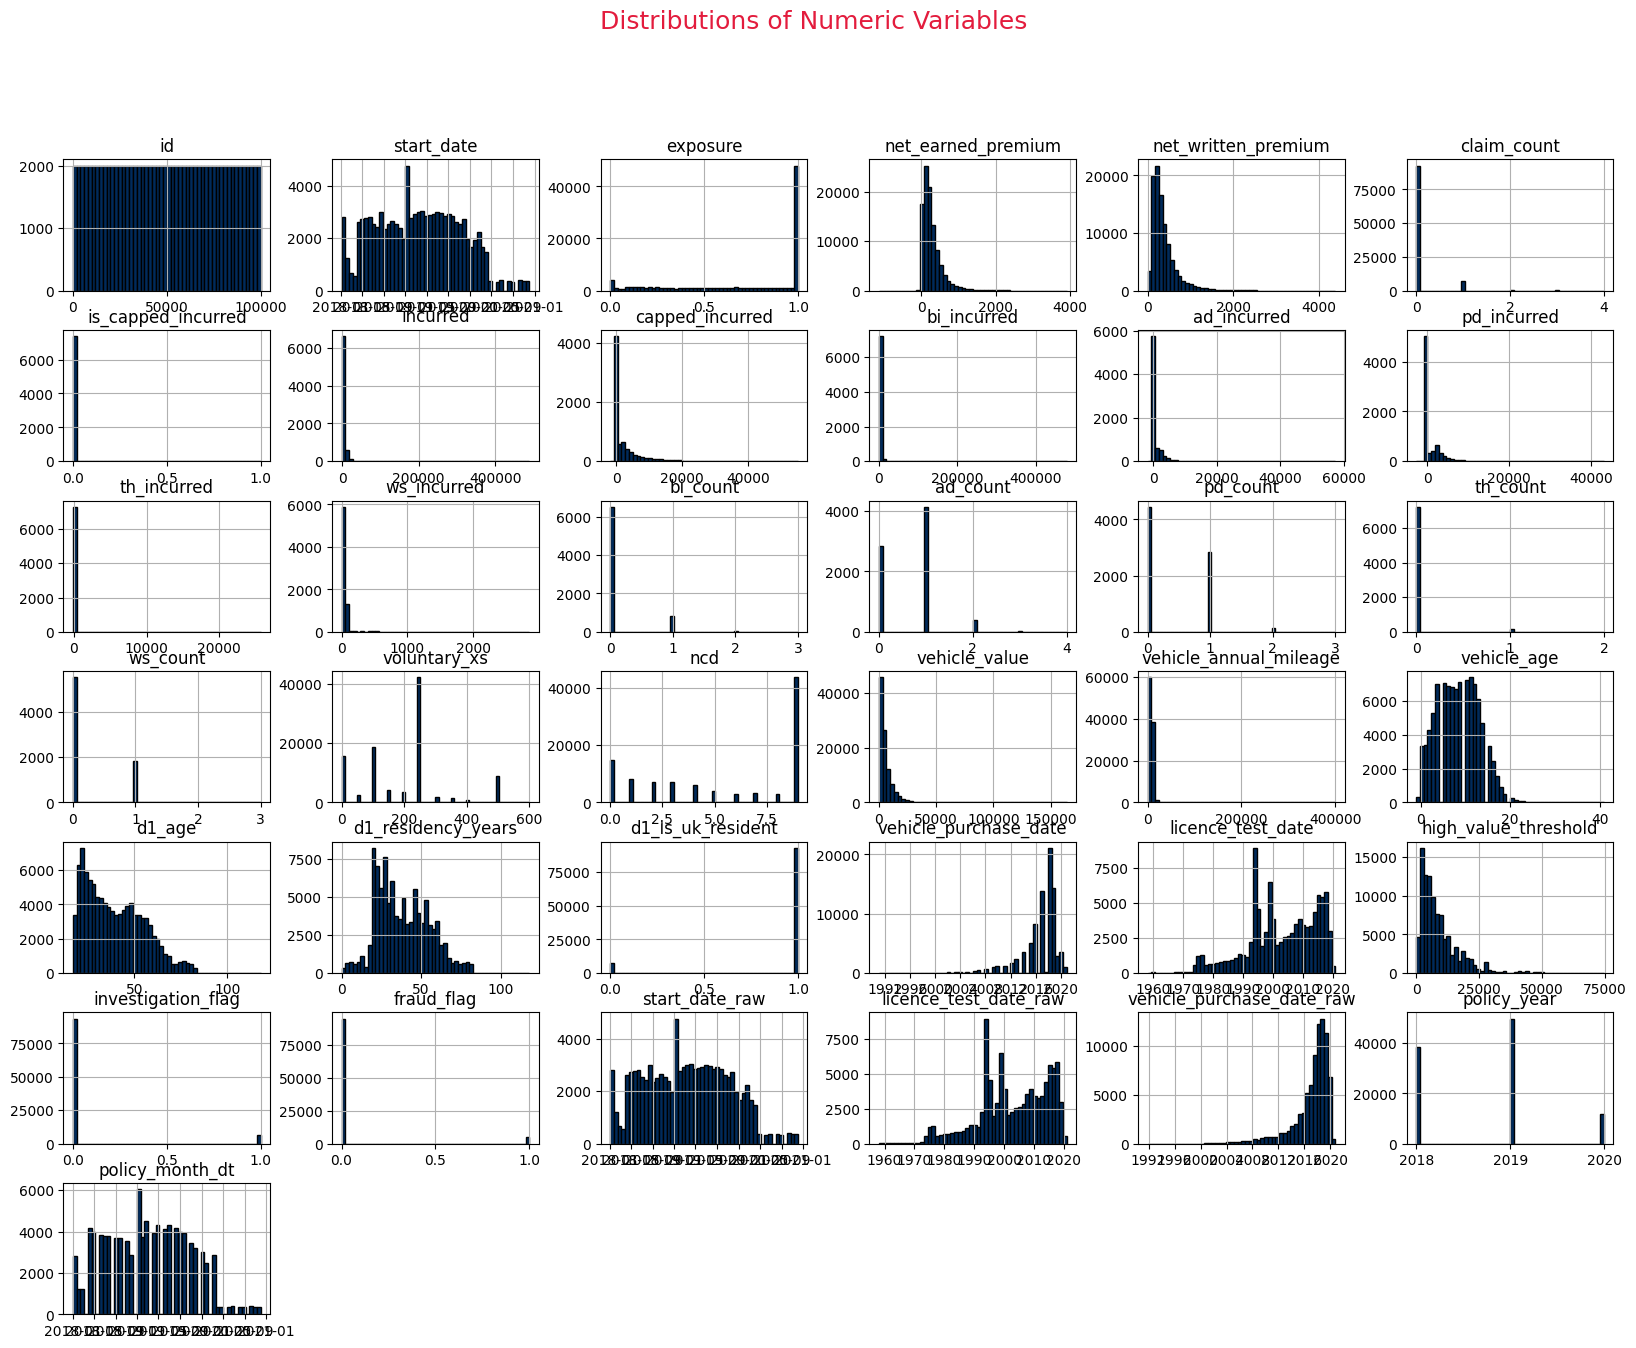

In [64]:
# 1. I plotted histogram for every numeric column to have an overview of the distribution and to spot outliers
df.hist(
    bins=50,
    figsize=(20, 15),
    color="#002B5C",
    edgecolor="black"
)

plt.suptitle("Distributions of Numeric Variables", fontsize=18, color="#E31C3D")
plt.show()


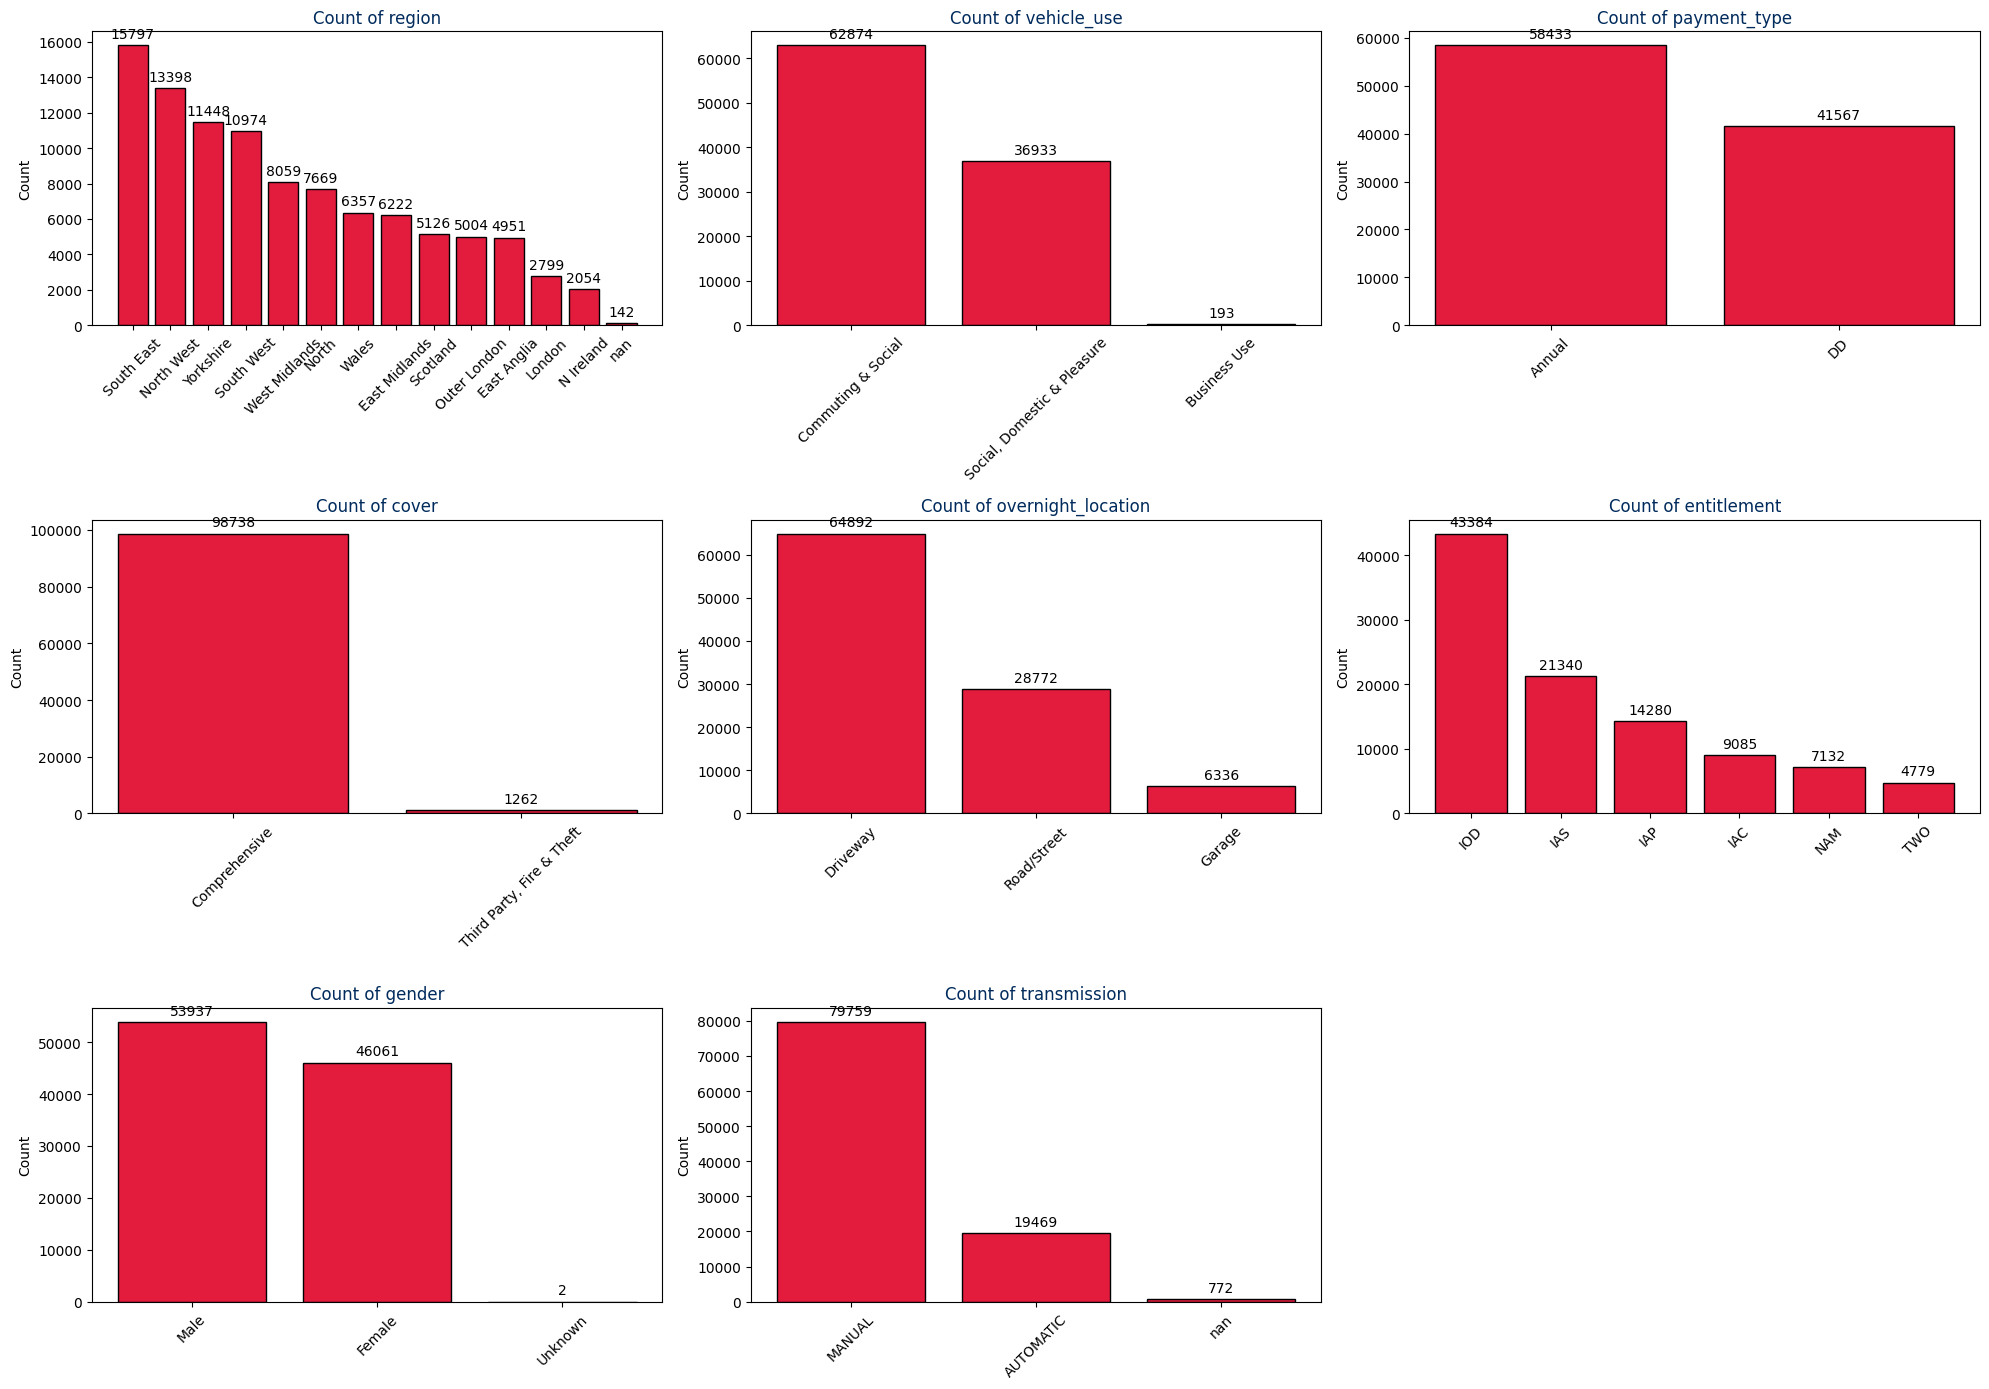

In [65]:
# 2. I plotted bar charts for the categorical columns but focused on key fraud-related ones as seen below
# A key change made here is replacing the abbreviations of the categorical columns into clearer terms using the data dictionary for better understanding 

df["cover"] = df["cover"].replace({
    "COMP": "Comprehensive",
    "TPFT": "Third Party, Fire & Theft"
})

df["vehicle_use"] = df["vehicle_use"].replace({
    "B": "Business Use",
    "C": "Commuting & Social",
    "S": "Social, Domestic & Pleasure"
})

df["overnight_location"] = df["overnight_location"].replace({
    "D": "Driveway",
    "G": "Garage",
    "R": "Road/Street"
})

categorical_vars = ["region", "vehicle_use", "payment_type", "cover", "overnight_location", "entitlement", "gender", "transmission"]

fig, axes = plt.subplots(3, 3, figsize=(20, 14))

# I flattened the axes array so it can loop easily
axes = axes.flatten()

for ax, col in zip(axes, categorical_vars):
    counts = df[col].value_counts(dropna=False)
    bars = ax.bar(counts.index.astype(str), counts.values, 
                  color="#E31C3D", edgecolor="black")

    ax.bar_label(bars, labels=[f"{v}" for v in counts.values], padding=3)

    ax.set_title(f"Count of {col}", fontsize=12, color="#002B5C")
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categorical_vars):]: ax.set_visible(False) # since i had an even number (8) of graphs to plot

plt.tight_layout()
plt.show()

KEY PERFORMANCE METRICS


In [66]:
# 1. VOLUME OF POLICIES AND FRAUD RATE

# The first step is to calculate the number of policies we have and this gives me a baseline data
# Note that to avoid duplicates, I am using the id column which is unique
total_policies = df["id"].nunique()

# Then, next I find the volume of fraudulent policies narrowing it to policies where the fraud_flag is 1
fraud_policies = df.loc[df["fraud_flag"] == 1, "id"].nunique()

investigated_policies = df.loc[df["investigation_flag"] == 1, "id"].nunique()
# A next important step is to understand the scale of fraud relative to Hastings Portfolio
fraud_rate = fraud_policies / total_policies * 100

print("Total policies:", total_policies)
print("Fraudulent policies:", fraud_policies)
print("Investigation policies:", investigated_policies)
print("Fraud rate (%):", round(fraud_rate, 2))



Total policies: 100000
Fraudulent policies: 4800
Investigation policies: 6575
Fraud rate (%): 4.8


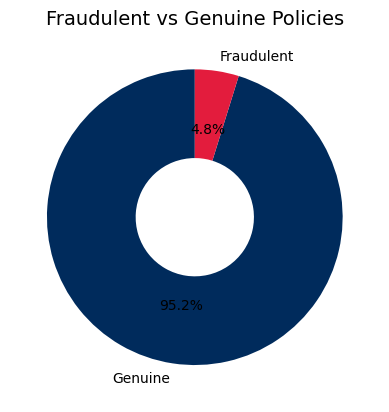

In [67]:
# 2. SIMPLE DONUT CHART SHOWING THE DISTRIBUTION OF POLICIES BASED ON FRAUD FLAG

Fraud = (df["fraud_flag"] == 1).sum()
Genuine = (df["fraud_flag"] == 0).sum()

plt.pie(
    [Genuine, Fraud],
    labels=["Genuine", "Fraudulent"],
    autopct="%.1f%%",
    colors=["#002B5C", "#E31C3D"], 
    startangle=90,
    wedgeprops=dict(width=0.6)
)

plt.title("Fraudulent vs Genuine Policies", fontsize=14)
plt.show()


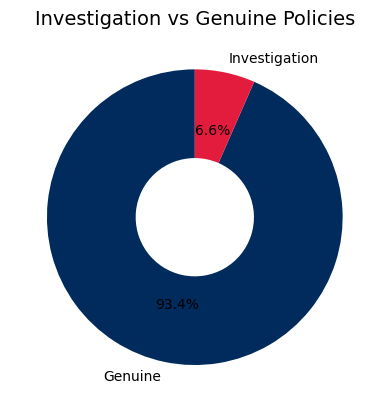

In [68]:
# 3. SIMPLE DONUT CHART SHOWING THE DISTRIBUTION OF POLICIES BASED ON INVESTIGATION FLAG

Investigation = (df["investigation_flag"] == 1).sum()
Genuine = (df["investigation_flag"] == 0).sum()

plt.pie(
    [Genuine, Investigation],
    labels=["Genuine", "Investigation"],
    autopct="%.1f%%",
    colors=["#002B5C", "#E31C3D"], 
    startangle=90,
    wedgeprops=dict(width=0.6)
)

plt.title("Investigation vs Genuine Policies", fontsize=14)
plt.show()

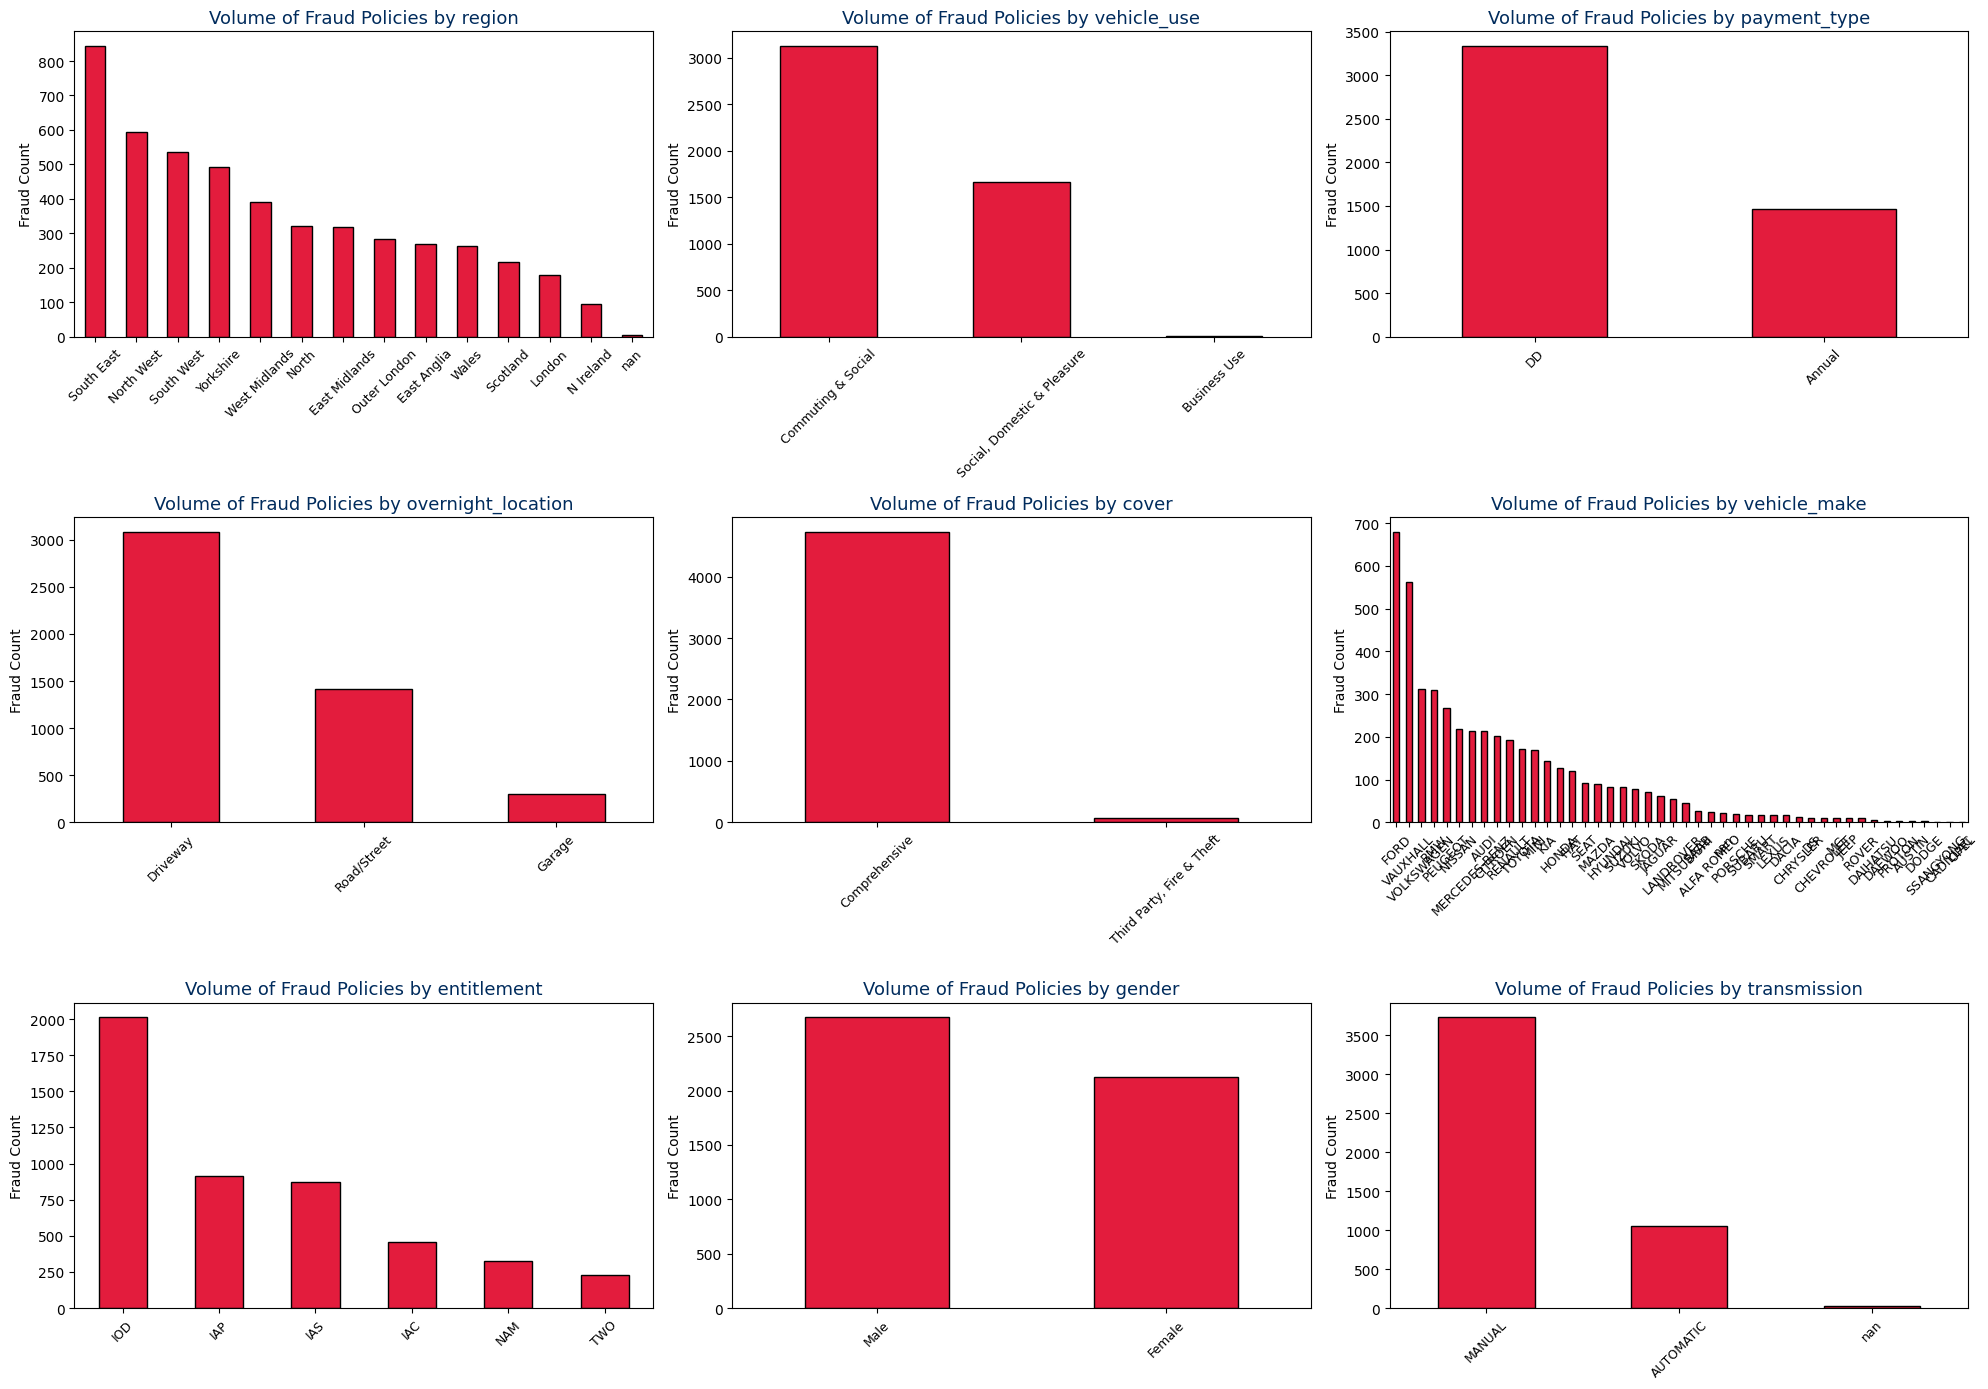

In [69]:
# 4. VOLUME OF FRAUD POLICIES BY CATEGORY
# It shows fraud prevalence by category or factors in the data


categorical_vars = ["region", "vehicle_use", "payment_type", "overnight_location", "cover", "vehicle_make", "entitlement", "gender", "transmission"]

fraud_df = df[df["fraud_flag"] == 1]  # Because I am only interested in cases where there is fraud

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
axes = axes.flatten()

for ax, col in zip(axes, categorical_vars):
    (fraud_df[col].value_counts(dropna=False)
                  .plot(kind="bar", ax=ax, color="#E31C3D", edgecolor="black"))
    
    ax.set_title(f"Volume of Fraud Policies by {col}", fontsize=13, color="#002B5C")
    ax.set_xlabel("")
    ax.set_ylabel("Fraud Count")
    ax.tick_params(axis="x", rotation=45, labelsize=9)

plt.tight_layout()
plt.show()


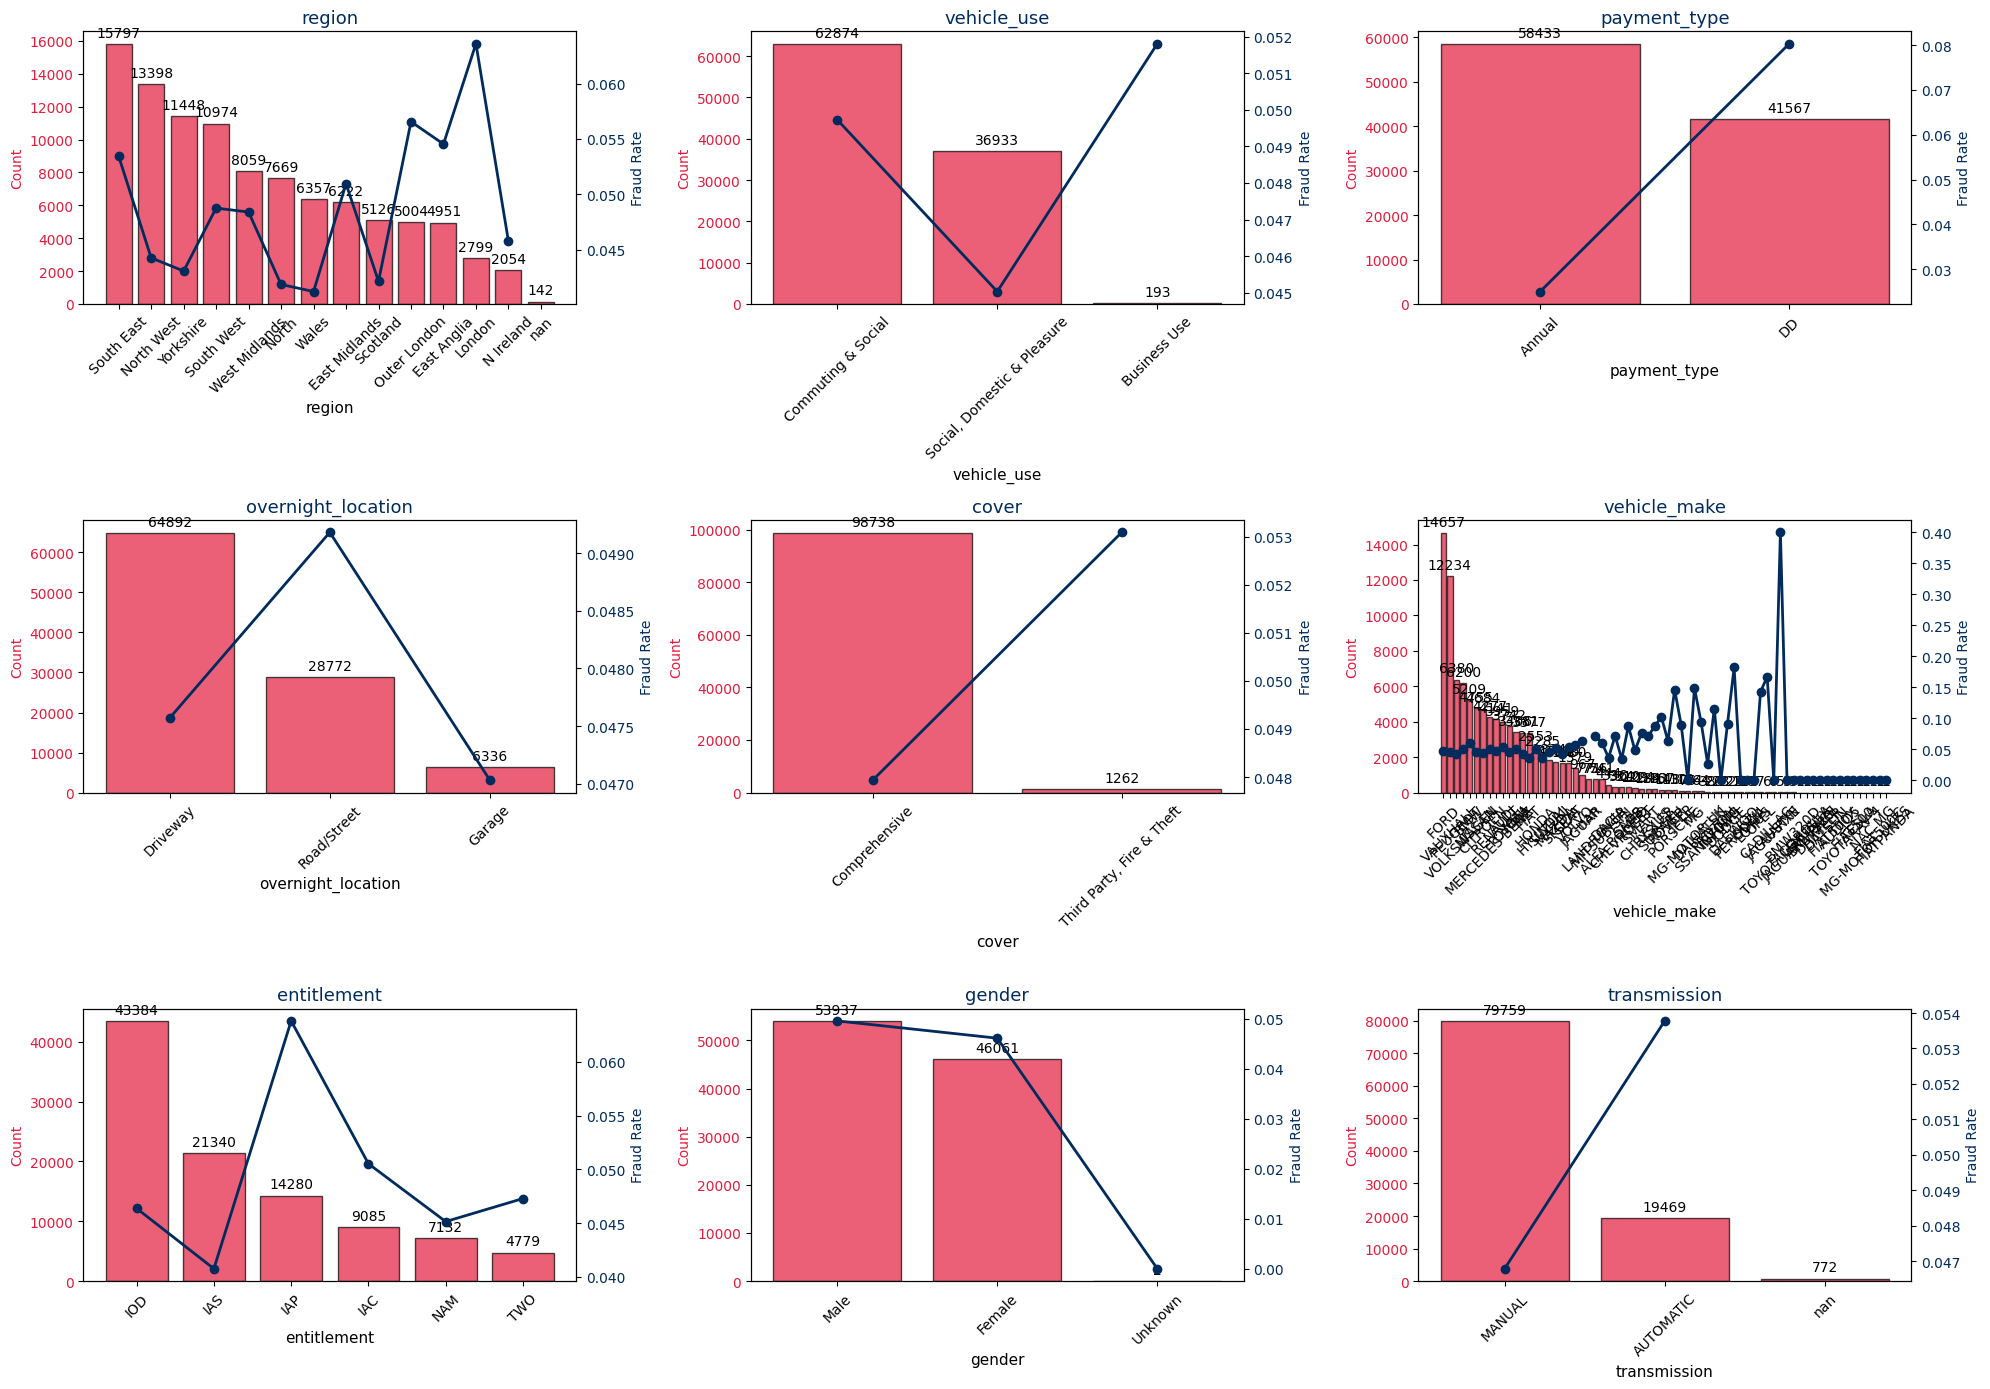

In [70]:
# 4. FRAUD PREVALENCE BY CATEGORY
# To create a clearer and impactful picture on fraud prevalence, I used dual-axis plots to display 
# not just the volume of policies by category but also the fraud rate. This way I can see both exposurre and risk 
# instead of focusing on just counts and overlooking high-risk categories

categorical_vars = ["region", "vehicle_use", "payment_type", "overnight_location", "cover", "vehicle_make", "entitlement", "gender", "transmission"]

fig, axes = plt.subplots(3, 3, figsize=(20, 14))
axes = axes.flatten()

for ax, col in zip(axes, categorical_vars):
    # Counts
    counts = df[col].value_counts(dropna=False)
    
    # Fraud rate
    fraud_rate = df.groupby(col)["fraud_flag"].mean().reindex(counts.index)
    
    # Bar plot (counts)
    bars = ax.bar(counts.index.astype(str), counts.values,
                  color="#E31C3D", edgecolor="black", alpha=0.7)
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel("Count", color="#E31C3D")
    ax.tick_params(axis="y", labelcolor="#E31C3D")
    ax.tick_params(axis="x", rotation=45)
    
    # Annotate counts on bars
    ax.bar_label(bars, labels=[f"{v}" for v in counts.values], padding=3)
    
    # Fraud rate (line plot on secondary y-axis)
    ax2 = ax.twinx()
    ax2.plot(counts.index.astype(str), fraud_rate.values,
             color="#002B5C", marker="o", linewidth=2)
    ax2.set_ylabel("Fraud Rate", color="#002B5C")
    ax2.tick_params(axis="y", labelcolor="#002B5C")
    
    # Title
    ax.set_title(f"{col}", fontsize=13, color="#002B5C")

# Hide any unused subplot axes (not needed here since we have exactly 9)
for ax in axes[len(categorical_vars):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


In [71]:
# LOSS RATIO
# overall loss ratio
total_claims = df["incurred"].sum()
total_premiums = df["net_earned_premium"].sum()
loss_ratio = (total_claims / total_premiums) * 100
print(f"Overall Loss Ratio: {loss_ratio:.2f}%")


Overall Loss Ratio: 77.20%


In [72]:
# LOSS RATIO FOR FRAUDULENT AND NON-FRAUDULENT POLICIES
loss_ratio_by_fraud = (
    df.groupby("fraud_flag")
      .apply(lambda g: g["incurred"].sum() / g["net_earned_premium"].sum() * 100)
      .reset_index(name="loss_ratio_%")
)

print(loss_ratio_by_fraud)


   fraud_flag  loss_ratio_%
0           0     49.665406
1           1    602.467460


C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\1533817346.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g["incurred"].sum() / g["net_earned_premium"].sum() * 100)


In [73]:
# CLAIMS FREQUENCY
# It simply tells me how many claims the company has in every 100 policies and it is a great sign of fraud risk

total_policies = df["id"].nunique()
total_claims = df["claim_count"].sum()

claims_frequency = total_claims / total_policies
print(f"Overall Claims Frequency: {claims_frequency:.2f} claims per policy")

# I compared it by fraud flag, that is, fraud and non-fraud
claims_freq_by_fraud = (
    df.groupby("fraud_flag")
      .agg(
          policies=("id", "nunique"),
          claims=("claim_count", "sum")
      )
      .assign(claims_frequency=lambda g: g["claims"] / g["policies"])
)

print("\nClaims Frequency by Fraud Flag:")
print(claims_freq_by_fraud)


Overall Claims Frequency: 0.08 claims per policy

Claims Frequency by Fraud Flag:
            policies  claims  claims_frequency
fraud_flag                                    
0              95200    4982          0.052332
1               4800    2982          0.621250


In [74]:
#CLAIMS SEVERITY
# This KPI gives me a clear picture of how much a claim costs Hastings Direct on average
total_incurred = df["incurred"].sum()
avg_claim_severity = total_incurred / total_claims
print(f"\nOverall Average Claim Severity: {avg_claim_severity:.2f}")

# I compared it by fraud status, that is, fraud and non-fraud
avg_severity_by_fraud = (
    df.groupby("fraud_flag")
      .agg(
          total_incurred=("incurred", "sum"),
          claims=("claim_count", "sum")
      )
      .assign(avg_claim_severity=lambda g: g["total_incurred"] / g["claims"])
)

print(avg_severity_by_fraud)



Overall Average Claim Severity: 2650.48
            total_incurred  claims  avg_claim_severity
fraud_flag                                            
0              12904273.86    4982         2590.179418
1               8204172.17    2982         2751.231445


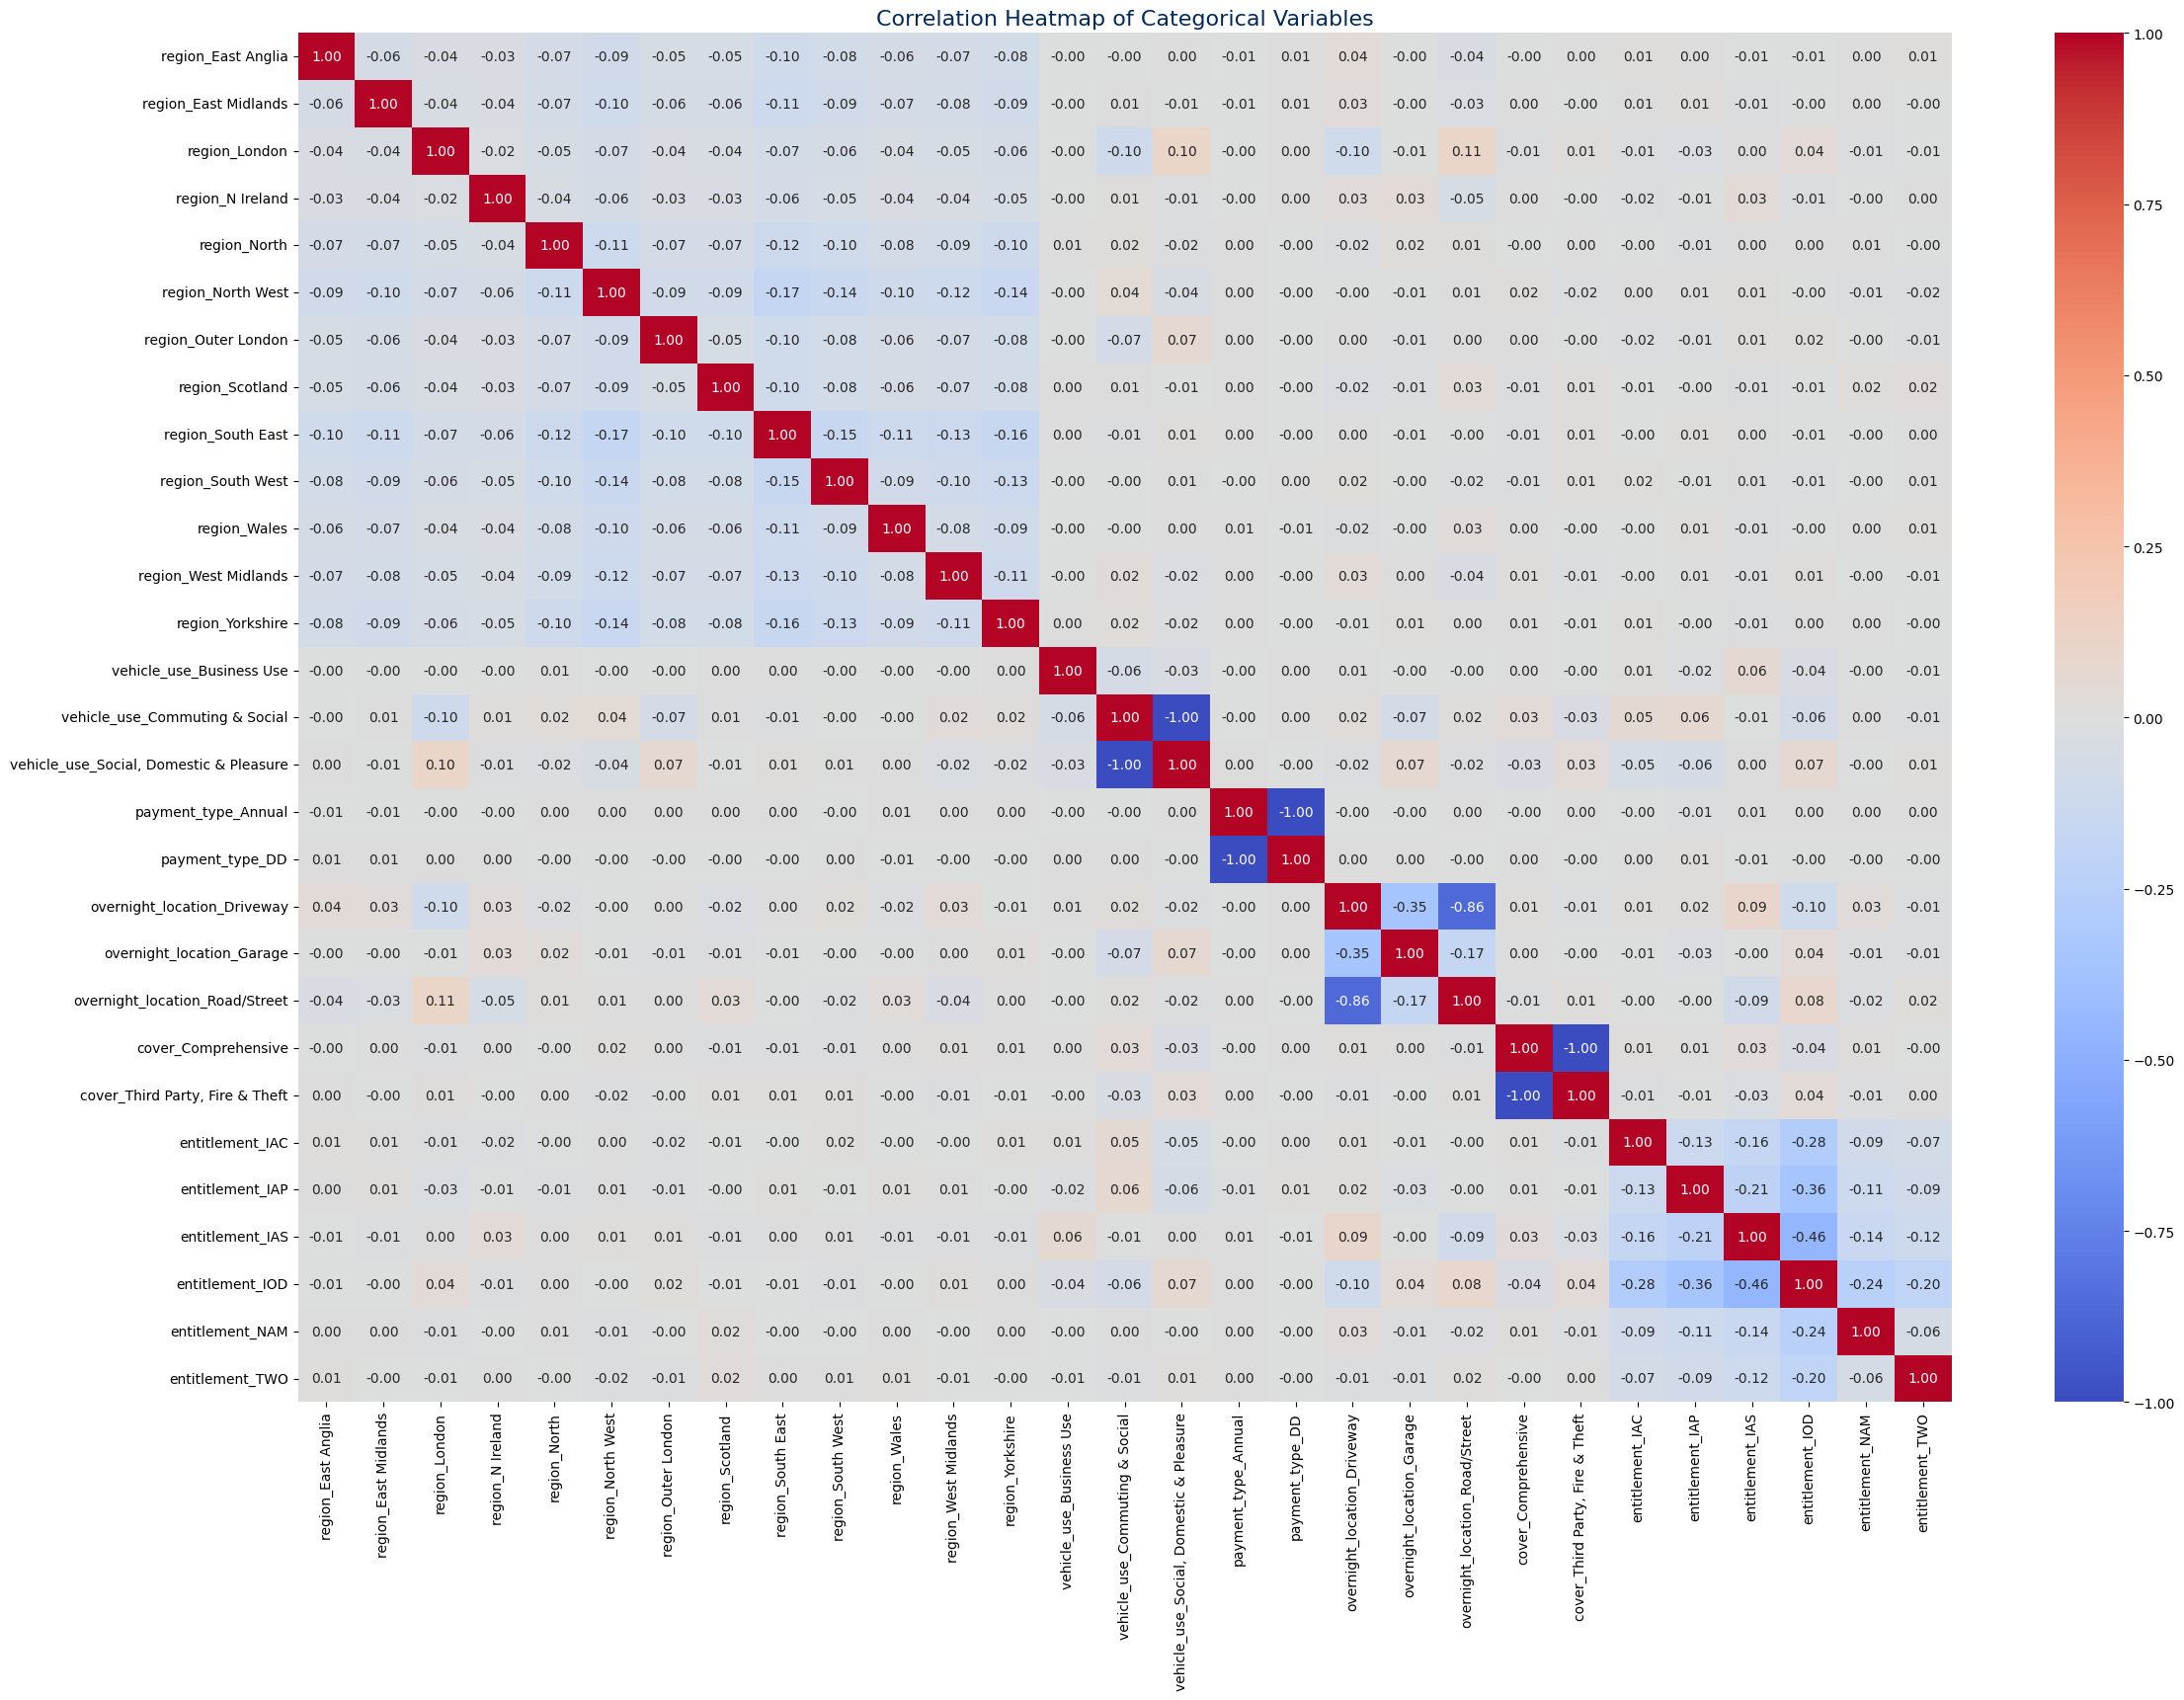

In [75]:
# 5. CORRELATION HEATMAP 

# I have redefined my categorical variables as seen below to capture key ones
categorical_vars = [
    "region", "vehicle_use", "payment_type", "overnight_location",
    "cover", "entitlement"
]

# I one-hot encoded the variables so I can get correlations between their levels and their relationships
df_dummies = pd.get_dummies(df[categorical_vars], drop_first=False)

corr_matrix = df_dummies.corr()

# Specifics for plotting the heatmap
plt.figure(figsize=(27,18))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,    # to show the value in cells and I have approx to 2 dp so it doesn't look untidy
    fmt=".2f",
    cbar=True
)
plt.title("Correlation Heatmap of Categorical Variables", fontsize=16, color="#002B5C")
plt.show()


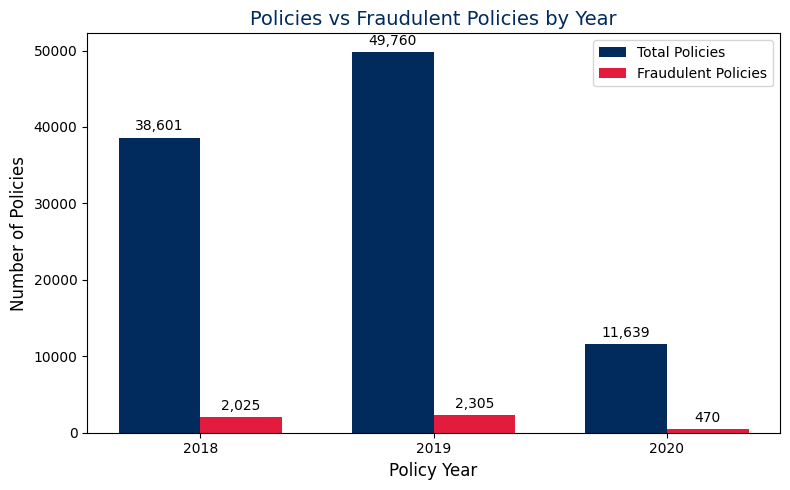

In [76]:
# 5. FRAUD TREND ANALYSIS BY YEAR
# An essential KPI in understanding the trend across the years (2018 -2020) of total and fraudulent policies

df["start_date"] = pd.to_datetime(df["start_date"], errors="coerce")

df["policy_year"] = df["start_date"].dt.year.astype("Int64")

fraud_by_year = (
    df.groupby("policy_year")
      .agg(
          total_policies=("id", "nunique"),
          fraudulent_policies=("fraud_flag", "sum")
      )
)

x = np.arange(len(fraud_by_year.index))
width = 0.35  

fig, ax = plt.subplots(figsize=(8,5))


bars1 = ax.bar(x - width/2, fraud_by_year["total_policies"],
               width, label="Total Policies", color="#002B5C")
bars2 = ax.bar(x + width/2, fraud_by_year["fraudulent_policies"],
               width, label="Fraudulent Policies", color="#E31C3D")

ax.set_title("Policies vs Fraudulent Policies by Year", fontsize=14, color="#002B5C")
ax.set_xlabel("Policy Year", fontsize=12)
ax.set_ylabel("Number of Policies", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(fraud_by_year.index.astype(int))

ax.bar_label(bars1, labels=[f"{v:,}" for v in fraud_by_year["total_policies"]], padding=3)
ax.bar_label(bars2, labels=[f"{v:,}" for v in fraud_by_year["fraudulent_policies"]], padding=3)

ax.legend()
plt.tight_layout()
plt.show()



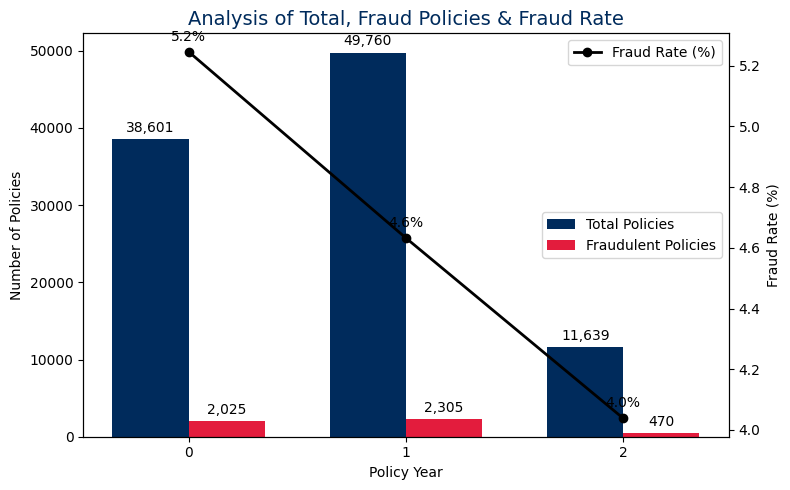

In [77]:
# 6. FRAUD TREND ANALYSIS AND FRAUD RATE BY YEAR

fraud_by_year["fraud_rate_%"] = (
    100 * fraud_by_year["fraudulent_policies"].div(fraud_by_year["total_policies"])
).fillna(0)

fig2, ax2 = plt.subplots(figsize=(8,5))

bars_total = ax2.bar(x - width/2, fraud_by_year["total_policies"], width, color="#002B5C", label="Total Policies")
bars_fraud = ax2.bar(x + width/2, fraud_by_year["fraudulent_policies"], width, color="#E31C3D", label="Fraudulent Policies")
ax2.set_ylabel("Number of Policies")
ax2.set_xlabel("Policy Year")
ax2.set_xticks(x)

# Fraud rate line
ax3 = ax2.twinx()
ax3.plot(x, fraud_by_year["fraud_rate_%"], color="black", marker="o", linewidth=2, label="Fraud Rate (%)")
ax3.set_ylabel("Fraud Rate (%)", color="black")


plt.title("Analysis of Total, Fraud Policies & Fraud Rate", fontsize=14, color="#002B5C")

# Annotate counts
ax2.bar_label(bars_total, labels=[f"{v:,}" for v in fraud_by_year["total_policies"]], padding=3)
ax2.bar_label(bars_fraud, labels=[f"{v:,}" for v in fraud_by_year["fraudulent_policies"]], padding=3)

# Annotate fraud rate %
for xi, rate in zip(x, fraud_by_year["fraud_rate_%"]):
    ax3.annotate(f"{rate:.1f}%", (xi, rate), textcoords="offset points", xytext=(0,8), ha="center")

# Legends
ax2.legend(loc="center right")
ax3.legend(loc="upper right")

plt.tight_layout()
plt.show()


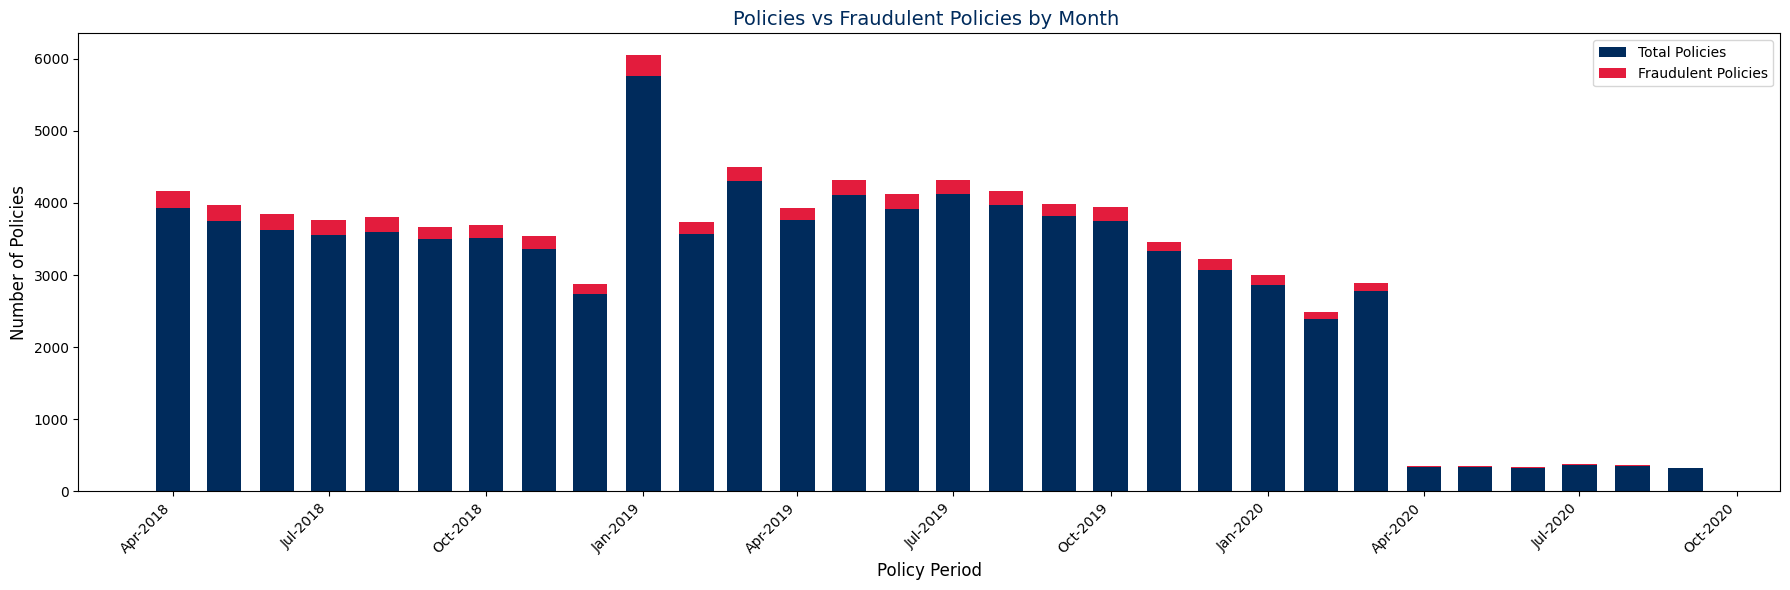

In [101]:
# 7. TREND ANALYSIS BY MONTH-YEAR

df["policy_month_dt"] = df["start_date"].dt.to_period("M").dt.to_timestamp() 

end = pd.Timestamp("2020-09-01")            
start = pd.Timestamp("2018-04-01")              
month_index = pd.date_range(start, end, freq="MS")

# Aggregate the policies by month and reindex 

fraud_by_month = (
    df.loc[df["policy_month_dt"] <= end]
      .groupby("policy_month_dt")
      .agg(
          total_policies=("id", "nunique"),
          fraudulent_policies=("fraud_flag", "sum")
      )
      .reindex(month_index, fill_value=0)
)

# Fraudulent policies are the red bars on the blue bars (total policies)
legit_bottom = fraud_by_month["total_policies"] - fraud_by_month["fraudulent_policies"]
legit_bottom = legit_bottom.clip(lower=0)  

fig, ax = plt.subplots(figsize=(18,6))

bar_width = 20

ax.bar(
    fraud_by_month.index,
    fraud_by_month["total_policies"],
    width=bar_width,
    color="#002B5C", label="Total Policies"
)

ax.bar(
    fraud_by_month.index,
    fraud_by_month["fraudulent_policies"],
    width=bar_width,
    bottom=legit_bottom,
    color="#E31C3D", label="Fraudulent Policies"
)

ax.set_title("Policies vs Fraudulent Policies by Month ", fontsize=14, color="#002B5C")
ax.set_xlabel("Policy Period", fontsize=12)
ax.set_ylabel("Number of Policies", fontsize=12)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%Y"))
fig.autofmt_xdate(rotation=45)

ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


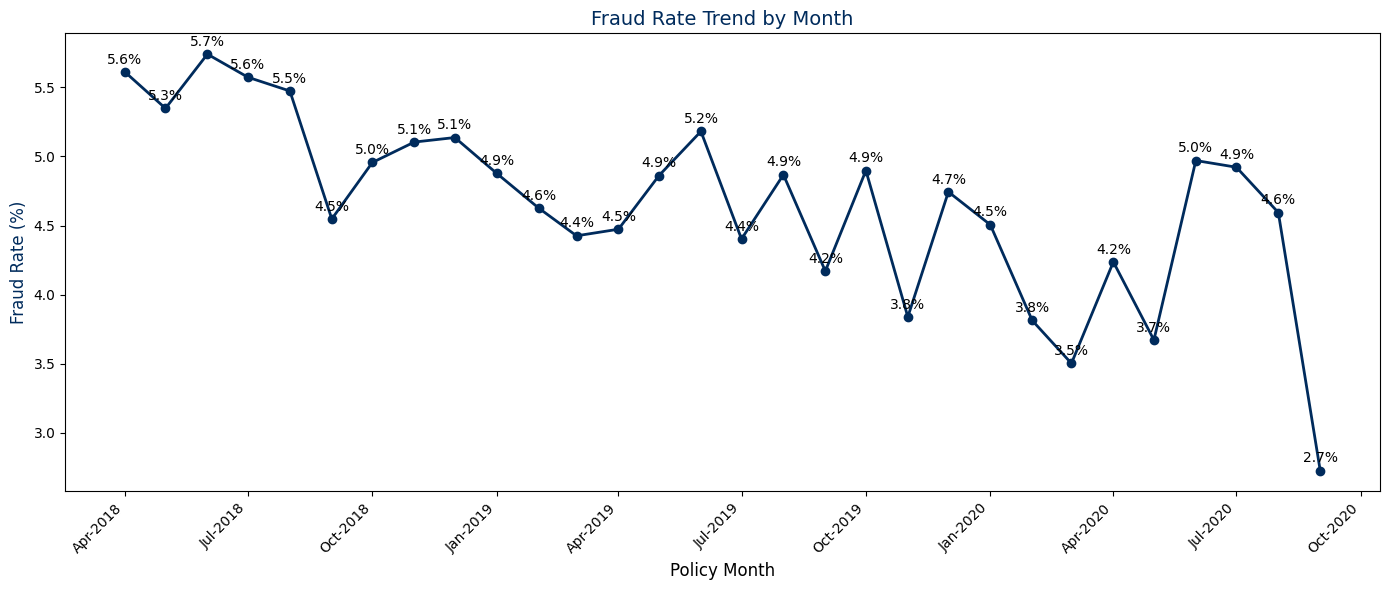

In [104]:
# 8. FRAUD RATE TREND BY MONTH-YEAR
# Gives an overview of the behaviour of the fraud rate over these 3 years

df["policy_month_dt"] = df["start_date"].dt.to_period("M").dt.to_timestamp()

end = pd.Timestamp("2020-09-01")                
start = pd.Timestamp("2018-04-01")
month_index = pd.date_range(start, end, freq="MS")

fraud_by_month = (
    df.loc[df["policy_month_dt"] <= end]
      .groupby("policy_month_dt")
      .agg(
          total_policies=("id", "nunique"),
          fraudulent_policies=("fraud_flag", "sum")
      )
      .reindex(month_index, fill_value=0)
)

fraud_by_month["fraud_rate_%"] = (
    fraud_by_month["fraudulent_policies"] / fraud_by_month["total_policies"] * 100
).replace([float("inf"), -float("inf")], 0).fillna(0)


fig, ax = plt.subplots(figsize=(14,6))

ax.plot(
    fraud_by_month.index,
    fraud_by_month["fraud_rate_%"],
    color="#002B5C", marker="o", linewidth=2
)

ax.set_title("Fraud Rate Trend by Month", fontsize=14, color="#002B5C")
ax.set_xlabel("Policy Month", fontsize=12)
ax.set_ylabel("Fraud Rate (%)", fontsize=12, color="#002B5C")

ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%Y"))
fig.autofmt_xdate(rotation=45)

# Annotate fraud rate on points
for x, y in zip(fraud_by_month.index, fraud_by_month["fraud_rate_%"]):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0,6), ha="center")

plt.tight_layout()
plt.show()


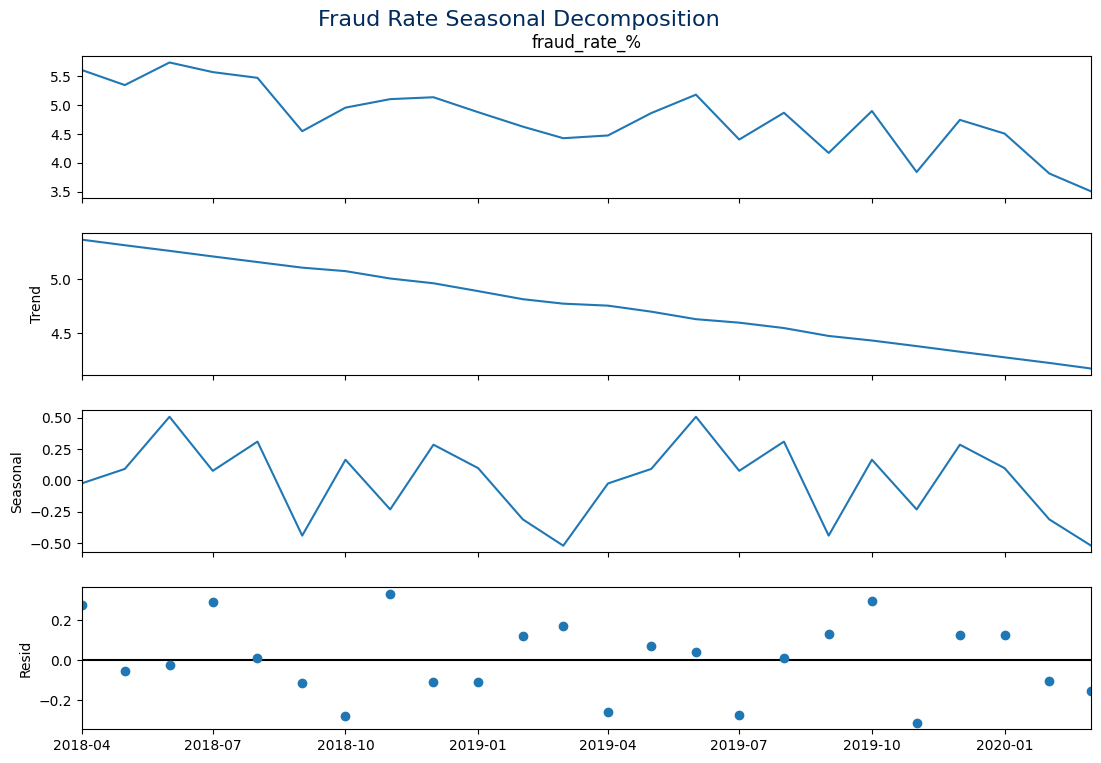

In [130]:
# SEASONAL DECOMPOSITION 
# 1. FRAUD RATE
# The idea here is to understand the trend, seasonality, and noise in the monthly fraud rate.
# In this case, I have narrowed the data to April 2018 to March 2020 so I have 2 full seasonal cycles

!pip install statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm

y = fraud_by_month.loc["2018-04-01":"2020-03-31","fraud_rate_%"].copy() # I used .copy() to create a standalone Series from the slice and avoid possible modifications in my df
y = y.asfreq("MS") 
y = y.sort_index()


res = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
fig = res.plot();
fig.set_size_inches(12, 8)
fig.suptitle("Fraud Rate Seasonal Decomposition", fontsize=16, color="#002B5C")
plt.show()



In [107]:
# Checking for its significance

trend = res.trend.dropna()

t = np.arange(len(trend))

X = sm.add_constant(t)

# I fitted the OLS regression
model = sm.OLS(trend.values, X).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 2.464e+04
Date:                Mon, 29 Sep 2025   Prob (F-statistic):           4.79e-35
Time:                        12:57:37   Log-Likelihood:                 74.994
No. Observations:                  24   AIC:                            -146.0
Df Residuals:                      22   BIC:                            -143.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.3601      0.004   1219.216      0.0

In [109]:
# 9. POLICIES BY MONTH
# I built a table to give me the numbers of the different KPIs already plotted so it stays handy for clearer insights
table = fraud_by_month.reset_index()
table.rename(columns={"index":"policy_month_dt"}, inplace=True)

# I formatted months as Mon-YYYY
table["policy_month"] = table["policy_month_dt"].dt.strftime("%b-%Y")

# Reorder columns
table = table[["policy_month", "total_policies", "fraudulent_policies"]]

table["fraud_rate_%"] = (table["fraudulent_policies"] / table["total_policies"] * 100).round(2)

table


,policy_month,total_policies,fraudulent_policies,fraud_rate_%
0,Apr-2018,4170,234,5.61
1,May-2018,3964,212,5.35
2,Jun-2018,3850,221,5.74
3,Jul-2018,3768,210,5.57
4,Aug-2018,3800,208,5.47
5,Sep-2018,3672,167,4.55
6,Oct-2018,3692,183,4.96
7,Nov-2018,3546,181,5.10
8,Dec-2018,2881,148,5.14
9,Jan-2019,6048,295,4.88


EFFICIENCY IN FRAUD DETECTION - UNDERSTANDING THE INVESTIGATION AND FRAUD FLAG

In [110]:
# 1. A key method of testing our efficiency is by calculating the investigation to fraud conversion rate.
""" It involves calculating the following:
       1. total volume of investigated policies (where investigation_flag == 1)
       2. total volume of fraudulent policies (where fraud_flag == 1)
       3. conversion rate 
"""
# Total investigated policies
investigations = (df["investigation_flag"] == 1).sum()

# Total fraudulent policies
frauds = (df["fraud_flag"] == 1).sum()

# Conversion rate
conversion_rate = (frauds / investigations * 100) if investigations > 0 else 0

print("Total Investigated Policies:", investigations)
print("Total Fraudulent Policies:", frauds)
print(f"Conversion Rate: {conversion_rate:.2f}%")


Total Investigated Policies: 6575
Total Fraudulent Policies: 4800
Conversion Rate: 73.00%


In [111]:
# 2. CONVERSION RATE TREND
df["start_date"] = pd.to_datetime(df["start_date"], errors="coerce")
df["policy_year"] = df["start_date"].dt.year

# Group by year
conversion_by_year = (
    df.groupby("policy_year")
      .agg(
          investigations=("investigation_flag", "sum"),
          frauds=("fraud_flag", "sum")
      )
)

conversion_by_year["conversion_rate_%"] = (
    conversion_by_year["frauds"] / conversion_by_year["investigations"] * 100
).round(2)

print(conversion_by_year)


             investigations  frauds  conversion_rate_%
policy_year                                           
2018                   3103    2025              65.26
2019                   3033    2305              76.00
2020                    439     470             107.06


In [112]:
# 2. FALSE POSITIVE RATE 

conversion_by_year = (
    df.groupby("policy_year")
      .agg(
          investigations=("investigation_flag", "sum"),
          frauds=("fraud_flag", "sum")
      )
)

# Conversion Rate (%)
conversion_by_year["conversion_rate_%"] = (
    conversion_by_year["frauds"] / conversion_by_year["investigations"] * 100
).round(2)

# False Positive Rate (%)
conversion_by_year["false_positive_rate_%"] = (
    (conversion_by_year["investigations"] - conversion_by_year["frauds"]) / conversion_by_year["investigations"] * 100
).round(2)

print(conversion_by_year)


             investigations  frauds  conversion_rate_%  false_positive_rate_%
policy_year                                                                  
2018                   3103    2025              65.26                  34.74
2019                   3033    2305              76.00                  24.00
2020                    439     470             107.06                  -7.06


C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\3146604658.py:48: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  inv_handle = plt.Rectangle((0, 0), 1, 1, color="#002B5C", edgecolor="black", label="Investigations")
C:\Users\emesa\AppData\Local\Temp\ipykernel_22084\3146604658.py:49: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  frd_handle = plt.Rectangle((0, 0), 1, 1, color="#E31C3D", edgecolor="black", label="Confirmed Frauds")


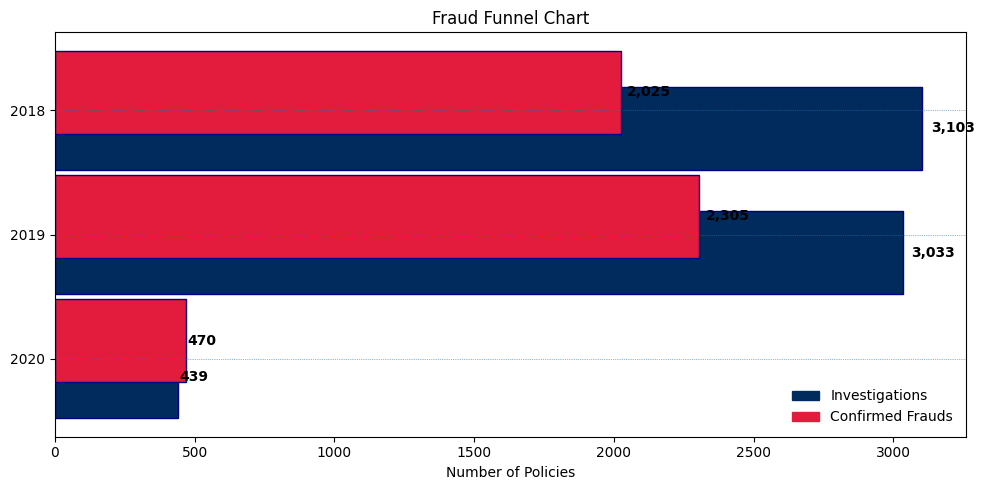

In [113]:
# 3. FRAUD FUNNEL CHART
# Pictures the conversion of investigation policies into fraud policies

# Using the data obtained in the conversion rate trend
years = [2018, 2019, 2020]
investigations = [3103, 3033, 439]
frauds = [2025, 2305, 470]

# Bar layout
gap = 0.35   
stride = 1.2 

y_positions = []
labels = []
bars_data = []
colors = []  

for i, yr in enumerate(years):
    base = i * stride
    y_inv = base + gap  # investigations 
    y_frd = base        # frauds 

    y_positions.extend([y_inv, y_frd])
    labels.extend([f"{yr} – Investigations", f"{yr} – Confirmed Frauds"])
    bars_data.extend([investigations[i], frauds[i]])

    colors.extend(["#002B5C", "#E31C3D"])

plt.figure(figsize=(10, 5))
bars = plt.barh(y_positions, bars_data, edgecolor="darkblue", color=colors)

# I assigned labels to value 
for b in bars:
    w = b.get_width()
    plt.text(w * 1.01, b.get_y() + b.get_height()/2, f"{int(w):,}", va="center", color="black", fontweight="bold")

plt.xlabel("Number of Policies")
plt.title("Fraud Funnel Chart")

year_centers = [i * stride + gap/2 for i in range(len(years))]
plt.yticks(year_centers, [str(y) for y in years])


for i, yr in enumerate(years):
    base = i * stride
    plt.axhline(base + gap/2, linestyle=":", linewidth=0.5)

inv_handle = plt.Rectangle((0, 0), 1, 1, color="#002B5C", edgecolor="black", label="Investigations")
frd_handle = plt.Rectangle((0, 0), 1, 1, color="#E31C3D", edgecolor="black", label="Confirmed Frauds")
plt.legend(handles=[inv_handle, frd_handle], loc="lower right", frameon=False)

plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


In [114]:
# 4. DECISION TREE MODEL FOR BETTER PREDICTION
# In order to make better predictions of high-risk policies and obtain more efficient rules for spotting possible fraud policies.
!pip install imbalanced-learn
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler

# I selected key categorical and numeric variables with insights from the correlation heatmap above
categorical_vars = [
    "region", "vehicle_use", "payment_type", "overnight_location",
    "cover", "entitlement"
]
numeric_vars = [
    "vehicle_value", "vehicle_annual_mileage", "vehicle_age", "d1_age", "net_written_premium"
]

# I encoded categorical variables
X_cat = pd.get_dummies(df[categorical_vars], drop_first=True)
X_num = df[numeric_vars].fillna(0) 
X = pd.concat([X_num, X_cat], axis=1)

# I assigned my target variable which in this case is the fraud flag
y = df["fraud_flag"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)


In [115]:
#I oversampled the training set of the minority class (fraud) to a ratio of 1:4

ros = RandomOverSampler(sampling_strategy=0.25, random_state=42)
X_train_res, y_train_res = ros.fit_resample(X_train, y_train)

In [116]:
# After carrying out my test split of 70, 30 and oversampling, I trained my decision tree
clf = DecisionTreeClassifier(
    criterion="gini",   
    max_depth=5,      
    random_state=42
)
clf.fit(X_train_res, y_train_res)


,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


              precision    recall  f1-score   support

           0       0.96      0.98      0.97     28560
           1       0.27      0.17      0.21      1440

    accuracy                           0.94     30000
   macro avg       0.62      0.57      0.59     30000
weighted avg       0.93      0.94      0.93     30000



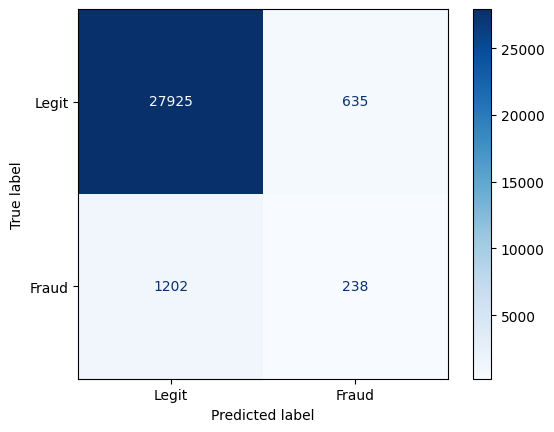

In [117]:
# Then, I made predictions
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legit", "Fraud"])
disp.plot(cmap="Blues")
plt.show()


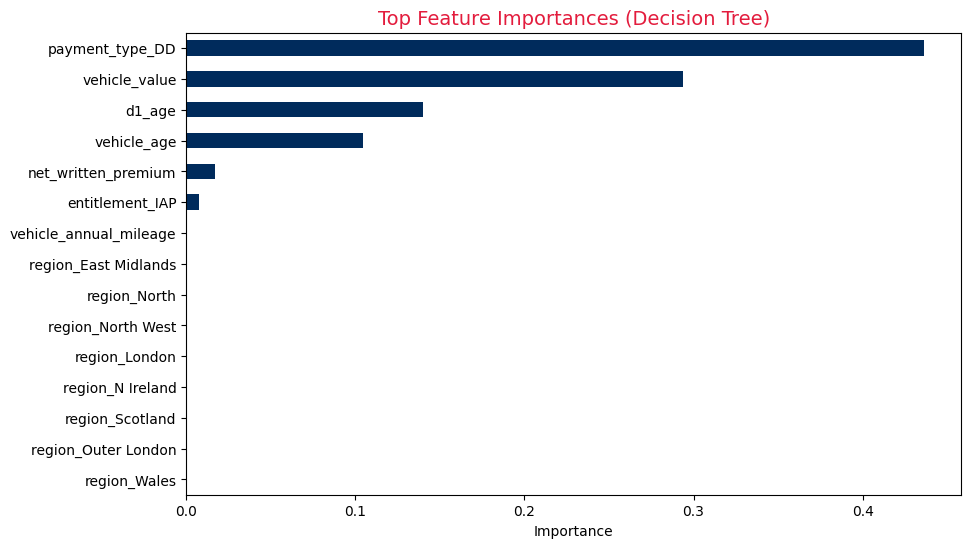

In [118]:
# 5. KEY FEATURES USING THE DECISION TREE

importances = pd.Series(clf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
importances.plot(kind="barh", color="#002B5C")
plt.title("Top Feature Importances (Decision Tree)", fontsize=14, color="#E31C3D")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()


In [119]:
# 6. DECISION RULES FOR IDENTIFYING POSSIBLE FRAUD POLICIES
from sklearn import tree

text_representation = tree.export_text(clf, feature_names=list(X.columns))
print(text_representation)


|--- payment_type_DD <= 0.50
|   |--- vehicle_age <= 10.50
|   |   |--- d1_age <= 65.50
|   |   |   |--- net_written_premium <= 128.30
|   |   |   |   |--- vehicle_annual_mileage <= 6949.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- vehicle_annual_mileage >  6949.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- net_written_premium >  128.30
|   |   |   |   |--- net_written_premium <= 128.33
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- net_written_premium >  128.33
|   |   |   |   |   |--- class: 0
|   |   |--- d1_age >  65.50
|   |   |   |--- class: 0
|   |--- vehicle_age >  10.50
|   |   |--- vehicle_value <= 2999.50
|   |   |   |--- vehicle_value <= 1999.50
|   |   |   |   |--- d1_age <= 60.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- d1_age >  60.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- vehicle_value >  1999.50
|   |   |   |   |--- vehicle_age <= 13.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- vehicle_age >  13.50
|  

In [120]:
from sklearn.tree import _tree

def tree_to_rules(clf, feature_names):
    tree_ = clf.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    rules = []

    def recurse(node, depth, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:  
            name = feature_name[node]
            threshold = tree_.threshold[node]

            # left branch
            recurse(tree_.children_left[node], depth + 1,
                    conditions + [f"{name} <= {threshold:.2f}"])

            # right branch
            recurse(tree_.children_right[node], depth + 1,
                    conditions + [f"{name} > {threshold:.2f}"])
        else: 
            value = tree_.value[node][0]
            samples = int(tree_.n_node_samples[node])
            pred_class = value.argmax()  # 0 = not fraud, 1 = fraud
            rules.append({
                "rule": "IF " + " AND ".join(conditions) + f" THEN class={pred_class}",
                "samples": samples,
                "distribution": value.astype(int).tolist()
            })

    recurse(0, 1, [])
    return rules


rules = tree_to_rules(clf, list(X.columns))
for r in rules[:10]:  # print first 10 rules
    print(f"{r['rule']}  [n={r['samples']}, dist={r['distribution']}]")


IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium <= 128.30 AND vehicle_annual_mileage <= 6949.50 THEN class=0  [n=1269, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium <= 128.30 AND vehicle_annual_mileage > 6949.50 THEN class=0  [n=841, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium > 128.30 AND net_written_premium <= 128.33 THEN class=1  [n=9, dist=[0, 1]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium > 128.30 AND net_written_premium > 128.33 THEN class=0  [n=25077, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age > 65.50 THEN class=0  [n=1566, dist=[1, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age > 10.50 AND vehicle_value <= 2999.50 AND vehicle_value <= 1999.50 AND d1_age <= 60.50 THEN class=0  [n=9625, dist=[0, 0]]
IF payment_type_DD <= 0

In [121]:
# Extract all rules
rules = tree_to_rules(clf, list(X.columns))

# Show 10 rules
for r in rules[:]:  
    dist = r['distribution']
    total = sum(dist)
    fraud_rate = dist[1] / total if total > 0 else 0
    print(f"{r['rule']}  "
          f"[n={r['samples']}, fraud_rate={fraud_rate:.2%}, dist={dist}]")


IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium <= 128.30 AND vehicle_annual_mileage <= 6949.50 THEN class=0  [n=1269, fraud_rate=0.00%, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium <= 128.30 AND vehicle_annual_mileage > 6949.50 THEN class=0  [n=841, fraud_rate=0.00%, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium > 128.30 AND net_written_premium <= 128.33 THEN class=1  [n=9, fraud_rate=100.00%, dist=[0, 1]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age <= 65.50 AND net_written_premium > 128.30 AND net_written_premium > 128.33 THEN class=0  [n=25077, fraud_rate=0.00%, dist=[0, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age <= 10.50 AND d1_age > 65.50 THEN class=0  [n=1566, fraud_rate=0.00%, dist=[1, 0]]
IF payment_type_DD <= 0.50 AND vehicle_age > 10.50 AND vehicle_value <= 2999.50 AND vehicle_valu

In [ ]:
# 7. XGBOOST MODEL
# This data has a major class imbalance problem as over 95% of the data is non-fraud so in the XgBoost model I will be applying oversampling
# I will be increasing the minority share to about 20% so the ratio between fraud and non-fraud class would be about 1:4 and that should give me a better model
# Also to handle oversampling, I chose to work with SMOTENC and not SMOTE because SMOTENC understands categorical variables better and won't create 
# fractional dummies for them.

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC

categorical_vars = [
    "region", "vehicle_use", "payment_type", "overnight_location",
    "cover", "entitlement"
]
numeric_vars = [
    "vehicle_value", "vehicle_annual_mileage", "vehicle_age",
    "d1_age", "net_written_premium"
]

# Here, I one-hot encoded categoricals and kept my numeric variables
X_cat = pd.get_dummies(df[categorical_vars], drop_first=True)
X_num = df[numeric_vars].fillna(0)
X = pd.concat([X_num, X_cat], axis=1)
y = df["fraud_flag"]


In [123]:

# Train and Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Applied SMOTENC for oversampling and a mask which simply identifies the variables that are categorical 
# and ones are numeric or continuous such that it doesn't interpolate values for the (one-hot encoded) categorical ones
all_cols = X_train.columns.tolist()
categorical_mask = [col not in numeric_vars for col in all_cols]

# SMOTENC on the training set after splitting to ensure that I don't leak the synthethic samples into the test set and affect model performance
smote = SMOTENC(
    categorical_features=categorical_mask,
    sampling_strategy=0.25,  # ensuring the ratio of 1:4 for fraud to non-fraud as already mentioned
    k_neighbors=5,
    random_state=42
)
X_train_res, y_train_res = smote.fit_resample(X_train.values, y_train.values)



In [124]:
# Train the model

clf = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    max_depth=5,
    n_estimators=400,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
)
clf.fit(X_train_res, y_train_res)



,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


              precision    recall  f1-score   support

           0     0.9548    0.9852    0.9697     28560
           1     0.2015    0.0743    0.1086      1440

    accuracy                         0.9414     30000
   macro avg     0.5781    0.5297    0.5391     30000
weighted avg     0.9186    0.9414    0.9284     30000



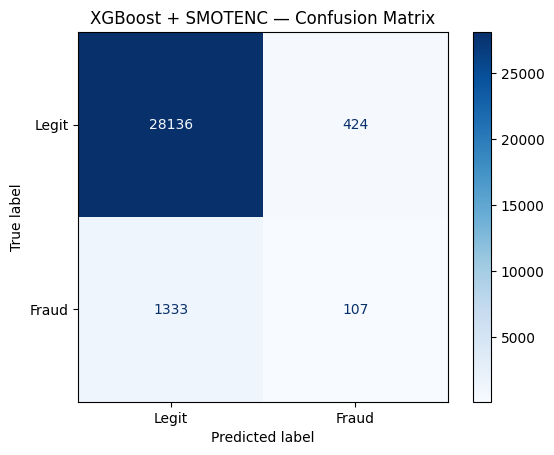

In [125]:
# Predicting and evaluating the model
y_pred = clf.predict(X_test.values)

print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legit", "Fraud"])
disp.plot(cmap="Blues")
plt.title("XGBoost + SMOTENC — Confusion Matrix")
plt.show()


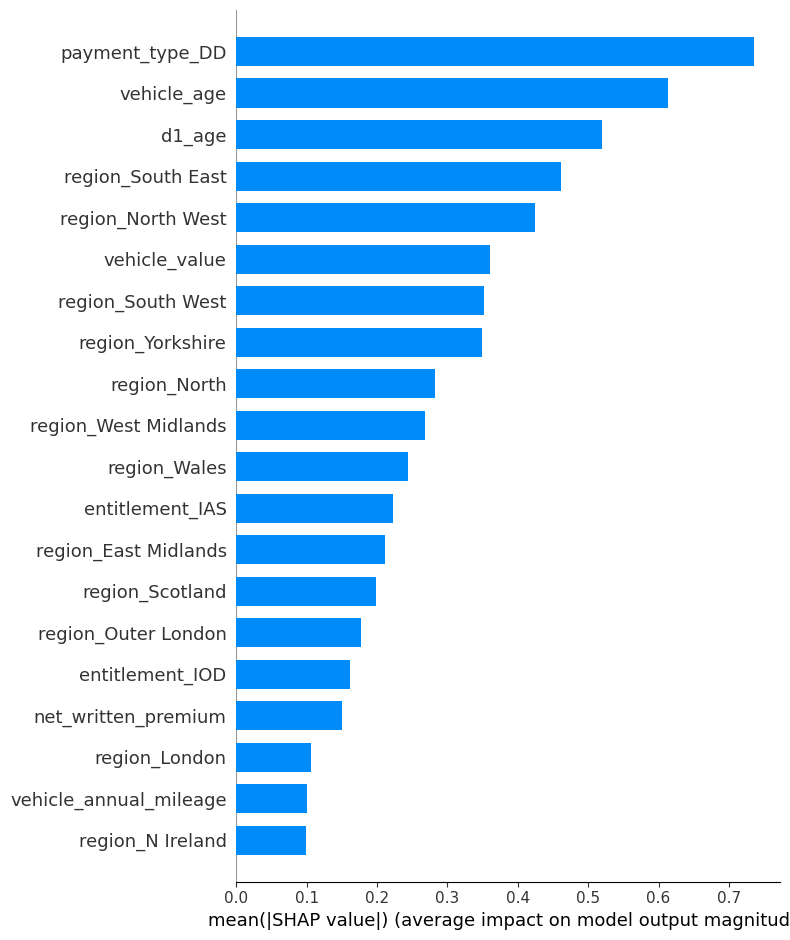

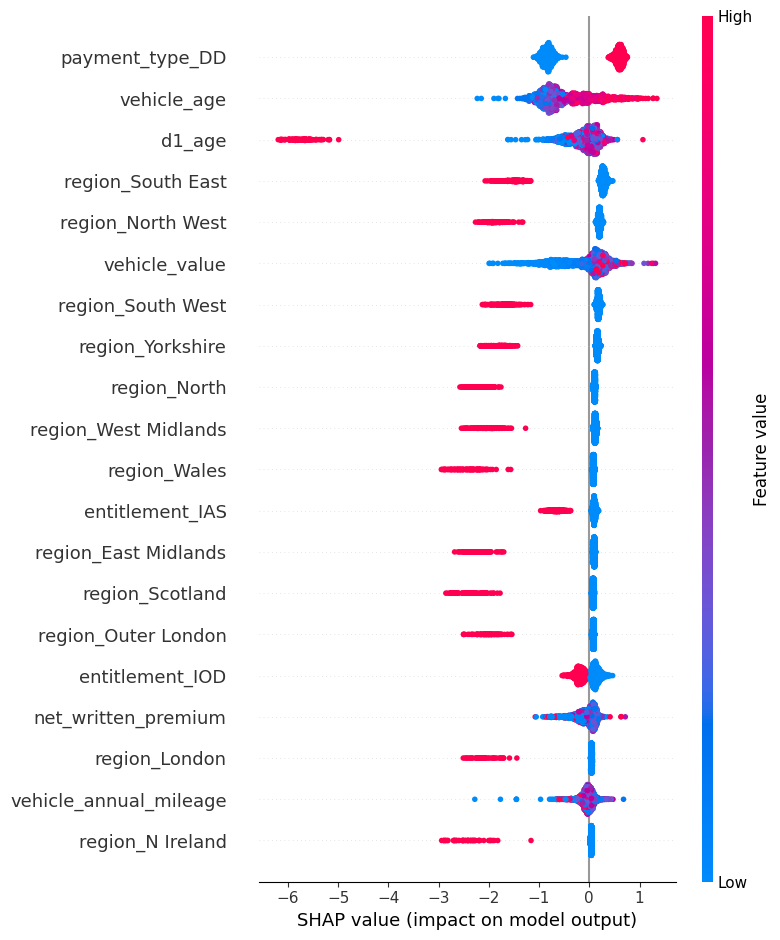

In [126]:
# SHAP Analysis
!pip install shap

import shap

explainer = shap.TreeExplainer(clf)

# Here, it computes SHAP values for the test set

X_sample = X_test.sample(2000, random_state=42) if len(X_test) > 2000 else X_test
shap_values = explainer.shap_values(X_sample)

# Summary plot (this summary displays both features/variables importance and direction)
shap.summary_plot(shap_values, X_sample, plot_type="bar")
shap.summary_plot(shap_values, X_sample)                 



In [131]:
!pip freeze > requirements.txt
